<a href="https://colab.research.google.com/github/Aparna1495/calibration-aware-vqc-layout-selection/blob/main/QML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q qiskit qiskit-aer qiskit-machine-learning \
    scikit-learn pandas numpy scipy matplotlib seaborn

In [ ]:
import qiskit
import qiskit_aer
import numpy as np

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("Environment ready!")

Qiskit: 2.6.2
Qiskit Aer: 0.18.2
Environment ready!


Experiment 01 — Candidate quantum circuit architectures

In [ ]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator

import numpy as np
import matplotlib.pyplot as plt

print("All imports successful")

All imports successful


In [ ]:
def create_candidate(n_qubits, layers, architecture):

    qc = QuantumCircuit(n_qubits)

    for layer in range(layers):

        # Parameterised single-qubit rotations
        for q in range(n_qubits):
            qc.ry(0.3 * (q + 1), q)
            qc.rz(0.2 * (q + 1), q)

        # Entanglement architecture
        if architecture == "linear":

            for q in range(n_qubits - 1):
                qc.cx(q, q + 1)

        elif architecture == "ring":

            for q in range(n_qubits - 1):
                qc.cx(q, q + 1)

            qc.cx(n_qubits - 1, 0)

    return qc


circuit_A = create_candidate(4, 2, "linear")
circuit_B = create_candidate(4, 2, "ring")

print("Architecture A: Linear")
print(circuit_A.draw(output="text"))

print("\nArchitecture B: Ring")
print(circuit_B.draw(output="text"))

Architecture A: Linear
     ┌─────────┐┌─────────┐     ┌─────────┐┌─────────┐                      »
q_0: ┤ Ry(0.3) ├┤ Rz(0.2) ├──■──┤ Ry(0.3) ├┤ Rz(0.2) ├────────────────■─────»
     ├─────────┤├─────────┤┌─┴─┐└─────────┘├─────────┤┌─────────┐   ┌─┴─┐   »
q_1: ┤ Ry(0.6) ├┤ Rz(0.4) ├┤ X ├─────■─────┤ Ry(0.6) ├┤ Rz(0.4) ├───┤ X ├───»
     ├─────────┤├─────────┤└───┘   ┌─┴─┐   └─────────┘├─────────┤┌──┴───┴──┐»
q_2: ┤ Ry(0.9) ├┤ Rz(0.6) ├────────┤ X ├────────■─────┤ Ry(0.9) ├┤ Rz(0.6) ├»
     ├─────────┤├─────────┤        └───┘      ┌─┴─┐   ├─────────┤├─────────┤»
q_3: ┤ Ry(1.2) ├┤ Rz(0.8) ├───────────────────┤ X ├───┤ Ry(1.2) ├┤ Rz(0.8) ├»
     └─────────┘└─────────┘                   └───┘   └─────────┘└─────────┘»
«               
«q_0: ──────────
«               
«q_1: ──■───────
«     ┌─┴─┐     
«q_2: ┤ X ├──■──
«     └───┘┌─┴─┐
«q_3: ─────┤ X ├
«          └───┘

Architecture B: Ring
     ┌─────────┐┌─────────┐                     ┌───┐┌─────────┐┌─────────┐»
q_0: ┤ Ry(0.3) ├┤ Rz(0.

In [ ]:
def circuit_metrics(qc):

    return {
        "Depth": qc.depth(),
        "Total gates": qc.size(),
        "Two-qubit gates": sum(
            1 for instruction in qc.data
            if len(instruction.qubits) == 2
        )
    }


print("Linear:", circuit_metrics(circuit_A))
print("Ring:", circuit_metrics(circuit_B))

Linear: {'Depth': 9, 'Total gates': 22, 'Two-qubit gates': 6}
Ring: {'Depth': 12, 'Total gates': 24, 'Two-qubit gates': 8}


In [ ]:
!pip install -q pylatexenc

print("Architecture A: Linear Entanglement")
print(circuit_A.draw(output="text"))

print("\nArchitecture B: Ring Entanglement")
print(circuit_B.draw(output="text"))

In [ ]:
print("Architecture A: Linear Entanglement")
print(circuit_A.draw(output="text"))

print("\nArchitecture B: Ring Entanglement")
print(circuit_B.draw(output="text"))

Architecture A: Linear Entanglement
     ┌─────────┐┌─────────┐     ┌─────────┐┌─────────┐                      »
q_0: ┤ Ry(0.3) ├┤ Rz(0.2) ├──■──┤ Ry(0.3) ├┤ Rz(0.2) ├────────────────■─────»
     ├─────────┤├─────────┤┌─┴─┐└─────────┘├─────────┤┌─────────┐   ┌─┴─┐   »
q_1: ┤ Ry(0.6) ├┤ Rz(0.4) ├┤ X ├─────■─────┤ Ry(0.6) ├┤ Rz(0.4) ├───┤ X ├───»
     ├─────────┤├─────────┤└───┘   ┌─┴─┐   └─────────┘├─────────┤┌──┴───┴──┐»
q_2: ┤ Ry(0.9) ├┤ Rz(0.6) ├────────┤ X ├────────■─────┤ Ry(0.9) ├┤ Rz(0.6) ├»
     ├─────────┤├─────────┤        └───┘      ┌─┴─┐   ├─────────┤├─────────┤»
q_3: ┤ Ry(1.2) ├┤ Rz(0.8) ├───────────────────┤ X ├───┤ Ry(1.2) ├┤ Rz(0.8) ├»
     └─────────┘└─────────┘                   └───┘   └─────────┘└─────────┘»
«               
«q_0: ──────────
«               
«q_1: ──■───────
«     ┌─┴─┐     
«q_2: ┤ X ├──■──
«     └───┘┌─┴─┐
«q_3: ─────┤ X ├
«          └───┘

Architecture B: Ring Entanglement
     ┌─────────┐┌─────────┐                     ┌───┐┌─────────┐┌─────────

In [ ]:
def get_circuit_metrics(circuit):
    two_qubit_gates = sum(
        len(instruction.qubits) == 2
        for instruction in circuit.data
    )

    return {
        "Qubits": circuit.num_qubits,
        "Circuit depth": circuit.depth(),
        "Total gates": circuit.size(),
        "Two-qubit gates": two_qubit_gates
    }

metrics_A = get_circuit_metrics(circuit_A)
metrics_B = get_circuit_metrics(circuit_B)

print("Architecture A — Linear")
for key, value in metrics_A.items():
    print(f"{key}: {value}")

print("\nArchitecture B — Ring")
for key, value in metrics_B.items():
    print(f"{key}: {value}")

Architecture A — Linear
Qubits: 4
Circuit depth: 9
Total gates: 22
Two-qubit gates: 6

Architecture B — Ring
Qubits: 4
Circuit depth: 12
Total gates: 24
Two-qubit gates: 8


Experiment 2 — Hardware-aware transpilation
Now we'll simulate a processor with four qubits connected in a linear chain:

In [ ]:
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

# Four-qubit linear hardware topology
coupling_map = CouplingMap.from_line(4)

# Same transpilation settings for both circuits
pm = generate_preset_pass_manager(
    optimization_level=1,
    coupling_map=coupling_map,
    basis_gates=["rz", "sx", "x", "cx"],
    seed_transpiler=42
)

# Transpile both architectures
transpiled_A = pm.run(circuit_A)
transpiled_B = pm.run(circuit_B)

# Calculate hardware-level resource metrics
def transpiled_metrics(circuit):
    return {
        "Depth": circuit.depth(),
        "Total gates": circuit.size(),
        "Two-qubit gates": sum(
            instruction.operation.num_qubits == 2
            for instruction in circuit.data
        ),
        "Gate breakdown": dict(circuit.count_ops())
    }

print("LINEAR ARCHITECTURE")
print(transpiled_metrics(transpiled_A))

print("\nRING ARCHITECTURE")
print(transpiled_metrics(transpiled_B))

LINEAR ARCHITECTURE
{'Depth': 13, 'Total gates': 38, 'Two-qubit gates': 6, 'Gate breakdown': {'sx': 16, 'rz': 16, 'cx': 6}}

RING ARCHITECTURE
{'Depth': 30, 'Total gates': 56, 'Two-qubit gates': 24, 'Gate breakdown': {'cx': 24, 'sx': 16, 'rz': 16}}


Experiment 3 — Investigate the routing overhead

In [ ]:
print("RING CIRCUIT AFTER TRANSPILATION")
print(transpiled_B.draw(output="text"))

print("\nINITIAL LAYOUT")
print(transpiled_B.layout.initial_layout)

print("\nFINAL LAYOUT")
print(transpiled_B.layout.final_layout)

RING CIRCUIT AFTER TRANSPILATION
         ┌────┐┌─────────────┐┌────┐┌─────────────┐          ┌───┐ »
q_3 -> 0 ┤ √X ├┤ Rz(-1.9416) ├┤ √X ├┤ Rz(-2.3416) ├──────────┤ X ├─»
         ├────┤├─────────────┤├────┤├─────────────┤     ┌───┐└─┬─┘ »
q_2 -> 1 ┤ √X ├┤ Rz(-2.2416) ├┤ √X ├┤ Rz(-2.5416) ├─────┤ X ├──■───»
         ├────┤├─────────────┤├────┤├─────────────┤┌───┐└─┬─┘┌────┐»
q_1 -> 2 ┤ √X ├┤ Rz(-2.5416) ├┤ √X ├┤ Rz(-2.7416) ├┤ X ├──■──┤ √X ├»
         ├────┤├─────────────┤├────┤├─────────────┤└─┬─┘     └────┘»
q_0 -> 3 ┤ √X ├┤ Rz(-2.8416) ├┤ √X ├┤ Rz(-2.9416) ├──■─────────────»
         └────┘└─────────────┘└────┘└─────────────┘                »
«                                                                     ┌───┐»
«q_3 -> 0 ────────────────────────────────────────────────────────────┤ X ├»
«              ┌────┐    ┌─────────────┐     ┌────┐    ┌─────────────┐└─┬─┘»
«q_2 -> 1 ─────┤ √X ├────┤ Rz(-2.2416) ├─────┤ √X ├────┤ Rz(-2.5416) ├──■──»
«         ┌────┴────┴───┐└────┬────┬──

In [ ]:
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

# Ring hardware connectivity
ring_hardware = CouplingMap([
    [0, 1], [1, 0],
    [1, 2], [2, 1],
    [2, 3], [3, 2],
    [3, 0], [0, 3]
])

pm_ring = generate_preset_pass_manager(
    optimization_level=1,
    coupling_map=ring_hardware,
    basis_gates=["rz", "sx", "x", "cx"],
    seed_transpiler=42
)

linear_on_ring = pm_ring.run(circuit_A)
ring_on_ring = pm_ring.run(circuit_B)

print("LINEAR CIRCUIT ON RING HARDWARE")
print(transpiled_metrics(linear_on_ring))

print("\nRING CIRCUIT ON RING HARDWARE")
print(transpiled_metrics(ring_on_ring))

LINEAR CIRCUIT ON RING HARDWARE
{'Depth': 13, 'Total gates': 38, 'Two-qubit gates': 6, 'Gate breakdown': {'sx': 16, 'rz': 16, 'cx': 6}}

RING CIRCUIT ON RING HARDWARE
{'Depth': 16, 'Total gates': 40, 'Two-qubit gates': 8, 'Gate breakdown': {'sx': 16, 'rz': 16, 'cx': 8}}


In [ ]:
import pandas as pd

results = pd.DataFrame([
    ["Linear", "Linear", 13, 38, 6],
    ["Linear", "Ring", 30, 56, 24],
    ["Ring", "Linear", 13, 38, 6],
    ["Ring", "Ring", 16, 40, 8]
], columns=[
    "Hardware",
    "Architecture",
    "Depth",
    "Total_Gates",
    "Two_Qubit_Gates"
])

display(results)

results.to_csv(
    "experiment_3_topology_comparison.csv",
    index=False
)

,Hardware,Architecture,Depth,Total_Gates,Two_Qubit_Gates
0,Linear,Linear,13,38,6
1,Linear,Ring,30,56,24
2,Ring,Linear,13,38,6
3,Ring,Ring,16,40,8


In [ ]:
display(results.style.hide(axis="index"))

results.to_csv(
    "experiment_3_topology_comparison.csv",
    index=False
)

Hardware,Architecture,Depth,Total_Gates,Two_Qubit_Gates
Linear,Linear,13,38,6
Linear,Ring,30,56,24
Ring,Linear,13,38,6
Ring,Ring,16,40,8


Experiment 4A — Define simulated hardware calibration

In [ ]:
# Synthetic calibration data
# Error rates are illustrative probabilities.

linear_calibration = {
    "single_qubit_error": {
        0: 0.0008,
        1: 0.0012,
        2: 0.0009,
        3: 0.0015
    },
    "two_qubit_error": {
        (0, 1): 0.008,
        (1, 2): 0.012,
        (2, 3): 0.009
    },
    "readout_error": {
        0: 0.015,
        1: 0.020,
        2: 0.018,
        3: 0.025
    }
}

ring_calibration = {
    "single_qubit_error": {
        0: 0.0008,
        1: 0.0012,
        2: 0.0009,
        3: 0.0015
    },
    "two_qubit_error": {
        (0, 1): 0.008,
        (1, 2): 0.012,
        (2, 3): 0.009,
        (0, 3): 0.010
    },
    "readout_error": {
        0: 0.015,
        1: 0.020,
        2: 0.018,
        3: 0.025
    }
}

print("Linear calibration profile:")
print(linear_calibration)

print("\nRing calibration profile:")
print(ring_calibration)

Linear calibration profile:
{'single_qubit_error': {0: 0.0008, 1: 0.0012, 2: 0.0009, 3: 0.0015}, 'two_qubit_error': {(0, 1): 0.008, (1, 2): 0.012, (2, 3): 0.009}, 'readout_error': {0: 0.015, 1: 0.02, 2: 0.018, 3: 0.025}}

Ring calibration profile:
{'single_qubit_error': {0: 0.0008, 1: 0.0012, 2: 0.0009, 3: 0.0015}, 'two_qubit_error': {(0, 1): 0.008, (1, 2): 0.012, (2, 3): 0.009, (0, 3): 0.01}, 'readout_error': {0: 0.015, 1: 0.02, 2: 0.018, 3: 0.025}}


In [ ]:
def estimate_noise_exposure(circuit, calibration):

    probabilities = []
    single_count = 0
    two_count = 0

    for instruction in circuit.data:

        operation = instruction.operation
        qubits = instruction.qubits

        physical_qubits = [
            circuit.find_bit(q).index for q in qubits
        ]

        if operation.name in ["sx", "x"]:
            q = physical_qubits[0]
            p = calibration["single_qubit_error"][q]
            probabilities.append(p)
            single_count += 1

        elif operation.name == "cx":
            q1, q2 = physical_qubits
            edge = tuple(sorted((q1, q2)))

            p = calibration["two_qubit_error"][edge]
            probabilities.append(p)
            two_count += 1

    survival_probability = np.prod(
        [1 - p for p in probabilities]
    )

    estimated_error = 1 - survival_probability

    return {
        "Single-qubit gates": single_count,
        "Two-qubit gates": two_count,
        "Estimated error probability": estimated_error
    }

In [ ]:
experiments = [
    ("Linear hardware", "Linear circuit",
     transpiled_A, linear_calibration),

    ("Linear hardware", "Ring circuit",
     transpiled_B, linear_calibration),

    ("Ring hardware", "Linear circuit",
     linear_on_ring, ring_calibration),

    ("Ring hardware", "Ring circuit",
     ring_on_ring, ring_calibration)
]

noise_results = []

for hardware, architecture, circuit, calibration in experiments:

    metrics = estimate_noise_exposure(
        circuit, calibration
    )

    noise_results.append({
        "Hardware": hardware,
        "Architecture": architecture,
        **metrics
    })

noise_df = pd.DataFrame(noise_results)

display(noise_df.style.format({
    "Estimated error probability": "{:.4%}"
}))

,Hardware,Architecture,Single-qubit gates,Two-qubit gates,Estimated error probability
0,Linear hardware,Linear circuit,16,6,7.3092%
1,Linear hardware,Ring circuit,16,24,21.5965%
2,Ring hardware,Linear circuit,16,6,7.3092%
3,Ring hardware,Ring circuit,16,8,9.1538%


Experiment 5 — Identify the best hardware–architecture combination

In [ ]:
# Add a normalised resource cost
noise_df["Normalised_2Q_Cost"] = (
    noise_df["Two-qubit gates"] /
    noise_df["Two-qubit gates"].max()
)

alpha = 0.7

noise_df["Selection_Score"] = (
    alpha * noise_df["Estimated error probability"] +
    (1 - alpha) * noise_df["Normalised_2Q_Cost"]
)

ranked_results = noise_df.sort_values(
    "Selection_Score"
).reset_index(drop=True)

display(
    ranked_results[[
        "Hardware",
        "Architecture",
        "Estimated error probability",
        "Two-qubit gates",
        "Selection_Score"
    ]]
)


,Hardware,Architecture,Estimated error probability,Two-qubit gates,Selection_Score
0,Linear hardware,Linear circuit,0.073092,6,0.126165
1,Ring hardware,Linear circuit,0.073092,6,0.126165
2,Ring hardware,Ring circuit,0.091538,8,0.164076
3,Linear hardware,Ring circuit,0.215965,24,0.451175


Experiment 6 — Build a QML classification dataset

In [ ]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Generate a reproducible binary classification dataset
X, y = make_classification(
    n_samples=100,
    n_features=4,
    n_informative=3,
    n_redundant=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=1.0,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Scale features to quantum rotation angles
scaler = MinMaxScaler(
    feature_range=(-np.pi, np.pi)
)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train_scaled))
print("Testing samples:", len(X_test_scaled))
print("Number of features:", X_train_scaled.shape[1])

print("\nFirst 5 scaled training samples:")
print(X_train_scaled[:5])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

Training samples: 75
Testing samples: 25
Number of features: 4

First 5 scaled training samples:
[[-0.0378899   1.56660903  0.11207308 -3.04047199]
 [ 0.53175598  1.36468653 -0.19830594 -1.87626452]
 [-0.43303318 -0.37364281 -0.47517446 -0.71495398]
 [ 3.14159265 -0.75695711  0.98467101 -2.35395742]
 [ 0.43924294  1.62140615 -0.70719207 -0.27446153]]

Training class distribution:
0    37
1    38
Name: count, dtype: int64


Experiment 7 — Build our first quantum classifiers

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# Four input features and eight trainable parameters
x_params = ParameterVector("x", 4)
theta = ParameterVector("theta", 8)

def build_vqc(architecture):

    qc = QuantumCircuit(4)

    # Feature encoding
    for q in range(4):
        qc.ry(x_params[q], q)
        qc.rz(x_params[q] / 2, q)

    # Trainable ansatz
    for q in range(4):
        qc.ry(theta[q], q)
        qc.rz(theta[q + 4], q)

    # Entanglement architecture
    if architecture == "linear":
        edges = [(0, 1), (1, 2), (2, 3)]

    elif architecture == "ring":
        edges = [(0, 1), (1, 2), (2, 3), (3, 0)]

    else:
        raise ValueError("Unknown architecture")

    for control, target in edges:
        qc.cx(control, target)

    return qc

vqc_linear = build_vqc("linear")
vqc_ring = build_vqc("ring")

print("LINEAR VQC")
print(vqc_linear.draw(output="text"))

print("\nRING VQC")
print(vqc_ring.draw(output="text"))

LINEAR VQC
     ┌──────────┐┌────────────┐┌──────────────┐┌──────────────┐               
q_0: ┤ Ry(x[0]) ├┤ Rz(x[0]/2) ├┤ Ry(theta[0]) ├┤ Rz(theta[4]) ├──■────────────
     ├──────────┤├────────────┤├──────────────┤├──────────────┤┌─┴─┐          
q_1: ┤ Ry(x[1]) ├┤ Rz(x[1]/2) ├┤ Ry(theta[1]) ├┤ Rz(theta[5]) ├┤ X ├──■───────
     ├──────────┤├────────────┤├──────────────┤├──────────────┤└───┘┌─┴─┐     
q_2: ┤ Ry(x[2]) ├┤ Rz(x[2]/2) ├┤ Ry(theta[2]) ├┤ Rz(theta[6]) ├─────┤ X ├──■──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤     └───┘┌─┴─┐
q_3: ┤ Ry(x[3]) ├┤ Rz(x[3]/2) ├┤ Ry(theta[3]) ├┤ Rz(theta[7]) ├──────────┤ X ├
     └──────────┘└────────────┘└──────────────┘└──────────────┘          └───┘

RING VQC
     ┌──────────┐┌────────────┐┌──────────────┐┌──────────────┐               »
q_0: ┤ Ry(x[0]) ├┤ Rz(x[0]/2) ├┤ Ry(theta[0]) ├┤ Rz(theta[4]) ├──■────────────»
     ├──────────┤├────────────┤├──────────────┤├──────────────┤┌─┴─┐          »
q_1: ┤ Ry(x[1]) ├┤ Rz(x[1]/2

In [ ]:
import numpy as np
from qiskit.quantum_info import Statevector, Pauli

observable = Pauli("IIIZ")

def quantum_prediction(circuit, sample, parameters):

    bindings = {
        x_params[q]: float(sample[q])
        for q in range(4)
    }

    bindings.update({
        theta[q]: float(parameters[q])
        for q in range(8)
    })

    bound_circuit = circuit.assign_parameters(bindings)

    state = Statevector.from_instruction(bound_circuit)

    expectation = state.expectation_value(observable).real

    return float(expectation)

In [ ]:
from scipy.optimize import minimize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

np.random.seed(42)

initial_parameters = np.random.uniform(
    -0.5, 0.5, 8
)

def objective(parameters, circuit, X_data, y_data):

    predictions = np.array([
        quantum_prediction(circuit, x, parameters)
        for x in X_data
    ])

    targets = 1 - 2 * y_data

    return np.mean((predictions - targets) ** 2)


def train_vqc(circuit):

    result = minimize(
        objective,
        initial_parameters.copy(),
        args=(circuit, X_train_scaled, y_train),
        method="COBYLA",
        options={"maxiter": 100, "rhobeg": 0.5}
    )

    return result


print("Training linear VQC...")
result_linear = train_vqc(vqc_linear)

print("Training ring VQC...")
result_ring = train_vqc(vqc_ring)

print("Linear training loss:", result_linear.fun)
print("Ring training loss:", result_ring.fun)

Training linear VQC...
Training ring VQC...
Linear training loss: 0.7868664713057392
Ring training loss: 0.9097009902240419


In [ ]:
def evaluate_vqc(circuit, parameters):

    expectations = np.array([
        quantum_prediction(circuit, x, parameters)
        for x in X_test_scaled
    ])

    probabilities = (1 - expectations) / 2

    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "Confusion Matrix": confusion_matrix(
            y_test, predictions
        ),
        "Predictions": predictions
    }


evaluation_linear = evaluate_vqc(
    vqc_linear, result_linear.x
)

evaluation_ring = evaluate_vqc(
    vqc_ring, result_ring.x
)

for name, result in [
    ("Linear VQC", evaluation_linear),
    ("Ring VQC", evaluation_ring)
]:
    print("\n", name)
    print("Accuracy:", result["Accuracy"])
    print("F1 Score:", result["F1 Score"])
    print("Confusion Matrix:\n", result["Confusion Matrix"])


 Linear VQC
Accuracy: 0.72
F1 Score: 0.6666666666666666
Confusion Matrix:
 [[11  2]
 [ 5  7]]

 Ring VQC
Accuracy: 0.52
F1 Score: 0.5384615384615384
Confusion Matrix:
 [[6 7]
 [5 7]]


Experiment 8 — Classical machine-learning baseline

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(
        random_state=42
    ),
    "RBF Support Vector Machine": SVC(
        kernel="rbf",
        random_state=42
    ),
    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    )
}

classical_results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    classical_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

classical_df = pd.DataFrame(classical_results)

display(classical_df)

,Model,Accuracy,F1 Score
0,Logistic Regression,0.92,0.916667
1,RBF Support Vector Machine,0.84,0.846154
2,Dummy Classifier,0.48,0.648649


In [ ]:
qml_results = pd.DataFrame([
    {
        "Model": "Linear VQC",
        "Accuracy": evaluation_linear["Accuracy"],
        "F1 Score": evaluation_linear["F1 Score"]
    },
    {
        "Model": "Ring VQC",
        "Accuracy": evaluation_ring["Accuracy"],
        "F1 Score": evaluation_ring["F1 Score"]
    }
])

all_results = pd.concat(
    [classical_df, qml_results],
    ignore_index=True
)

display(
    all_results.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Model,Accuracy,F1 Score
0,Logistic Regression,0.92,0.916667
1,RBF Support Vector Machine,0.84,0.846154
3,Linear VQC,0.72,0.666667
4,Ring VQC,0.52,0.538462
2,Dummy Classifier,0.48,0.648649


Experiment 9 — Test whether the VQC results are reproducible

In [ ]:
repeated_results = []

for architecture, circuit in [
    ("Linear VQC", vqc_linear),
    ("Ring VQC", vqc_ring)
]:

    for seed in range(5):

        rng = np.random.default_rng(seed)

        initial = rng.uniform(-0.5, 0.5, 8)

        result = minimize(
            objective,
            initial,
            args=(circuit, X_train_scaled, y_train),
            method="COBYLA",
            options={
                "maxiter": 100,
                "rhobeg": 0.5
            }
        )

        evaluation = evaluate_vqc(
            circuit,
            result.x
        )

        repeated_results.append({
            "Architecture": architecture,
            "Seed": seed,
            "Training loss": result.fun,
            "Accuracy": evaluation["Accuracy"],
            "F1 Score": evaluation["F1 Score"]
        })

repeated_df = pd.DataFrame(repeated_results)

display(repeated_df)

,Architecture,Seed,Training loss,Accuracy,F1 Score
0,Linear VQC,0,0.786866,0.72,0.666667
1,Linear VQC,1,0.786866,0.72,0.666667
2,Linear VQC,2,0.786866,0.72,0.666667
3,Linear VQC,3,0.786866,0.72,0.666667
4,Linear VQC,4,0.786866,0.72,0.666667
5,Ring VQC,0,0.909701,0.52,0.538462
6,Ring VQC,1,0.933234,0.52,0.500000
7,Ring VQC,2,0.909701,0.52,0.538462
8,Ring VQC,3,0.909701,0.52,0.538462
9,Ring VQC,4,0.909701,0.52,0.538462


In [ ]:
summary_df = (
    repeated_df
    .groupby("Architecture")
    .agg({
        "Training loss": ["mean", "std"],
        "Accuracy": ["mean", "std"],
        "F1 Score": ["mean", "std"]
    })
)

display(summary_df)

Training loss               Accuracy       F1 Score          
                      mean           std     mean  std      mean       std
Architecture                                                              
Linear VQC        0.786866  4.499606e-12     0.72  0.0  0.666667  0.000000
Ring VQC          0.914408  1.052446e-02     0.52  0.0  0.530769  0.017201


Experiment 9 — Test whether the VQC results are reproducible

In [ ]:
repeated_results = []

for architecture, circuit in [
    ("Linear VQC", vqc_linear),
    ("Ring VQC", vqc_ring)
]:

    for seed in range(5):

        rng = np.random.default_rng(seed)

        initial = rng.uniform(-0.5, 0.5, 8)

        result = minimize(
            objective,
            initial,
            args=(circuit, X_train_scaled, y_train),
            method="COBYLA",
            options={
                "maxiter": 100,
                "rhobeg": 0.5
            }
        )

        evaluation = evaluate_vqc(
            circuit,
            result.x
        )

        repeated_results.append({
            "Architecture": architecture,
            "Seed": seed,
            "Training loss": result.fun,
            "Accuracy": evaluation["Accuracy"],
            "F1 Score": evaluation["F1 Score"]
        })

repeated_df = pd.DataFrame(repeated_results)

display(repeated_df)

,Architecture,Seed,Training loss,Accuracy,F1 Score
0,Linear VQC,0,0.786866,0.72,0.666667
1,Linear VQC,1,0.786866,0.72,0.666667
2,Linear VQC,2,0.786866,0.72,0.666667
3,Linear VQC,3,0.786866,0.72,0.666667
4,Linear VQC,4,0.786866,0.72,0.666667
5,Ring VQC,0,0.909701,0.52,0.538462
6,Ring VQC,1,0.933234,0.52,0.500000
7,Ring VQC,2,0.909701,0.52,0.538462
8,Ring VQC,3,0.909701,0.52,0.538462
9,Ring VQC,4,0.909701,0.52,0.538462


In [ ]:
summary_df = (
    repeated_df
    .groupby("Architecture")
    .agg({
        "Training loss": ["mean", "std"],
        "Accuracy": ["mean", "std"],
        "F1 Score": ["mean", "std"]
    })
)

display(summary_df)

Training loss               Accuracy       F1 Score          
                      mean           std     mean  std      mean       std
Architecture                                                              
Linear VQC        0.786866  4.499606e-12     0.72  0.0  0.666667  0.000000
Ring VQC          0.914408  1.052446e-02     0.52  0.0  0.530769  0.017201

In [ ]:
required = [
    "linear_noise",
    "ring_noise",
    "linear_simulator",
    "ring_simulator",
    "compiled_circuits",
    "result_linear",
    "result_ring"
]

for name in required:
    print(name, ":", name in globals())

linear_noise : False
ring_noise : False
linear_simulator : False
ring_simulator : False
compiled_circuits : False
result_linear : True
result_ring : True


Experiment 10 — Recovery

In [ ]:
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# Recreate synthetic calibration profiles
linear_calibration = {
    "single_qubit_error": {
        0: 0.0008, 1: 0.0012, 2: 0.0009, 3: 0.0015
    },
    "two_qubit_error": {
        (0, 1): 0.008, (1, 2): 0.012, (2, 3): 0.009
    },
    "readout_error": {
        0: 0.015, 1: 0.020, 2: 0.018, 3: 0.025
    }
}

ring_calibration = {
    "single_qubit_error": {
        0: 0.0008, 1: 0.0012, 2: 0.0009, 3: 0.0015
    },
    "two_qubit_error": {
        (0, 1): 0.008, (1, 2): 0.012,
        (2, 3): 0.009, (0, 3): 0.010
    },
    "readout_error": {
        0: 0.015, 1: 0.020, 2: 0.018, 3: 0.025
    }
}

def build_noise_model(calibration):
    noise = NoiseModel()

    for q, p in calibration["single_qubit_error"].items():
        noise.add_quantum_error(
            depolarizing_error(p, 1), ["sx", "x"], [q]
        )

    for (q1, q2), p in calibration["two_qubit_error"].items():
        error = depolarizing_error(p, 2)

        noise.add_quantum_error(error, "cx", [q1, q2])
        noise.add_quantum_error(error, "cx", [q2, q1])

    return noise

linear_noise = build_noise_model(linear_calibration)
ring_noise = build_noise_model(ring_calibration)

linear_simulator = AerSimulator(
    method="density_matrix",
    noise_model=linear_noise
)

ring_simulator = AerSimulator(
    method="density_matrix",
    noise_model=ring_noise
)

print("Linear noise model:", linear_noise)
print("Ring noise model:", ring_noise)
print("Both simulators created successfully.")

Linear noise model: NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['cx', 'sx', 'x']
  Qubits with noise: [0, 1, 2, 3]
  Specific qubit errors: [('sx', (0,)), ('sx', (1,)), ('sx', (2,)), ('sx', (3,)), ('x', (0,)), ('x', (1,)), ('x', (2,)), ('x', (3,)), ('cx', (0, 1)), ('cx', (1, 0)), ('cx', (1, 2)), ('cx', (2, 1)), ('cx', (2, 3)), ('cx', (3, 2))]
Ring noise model: NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['cx', 'sx', 'x']
  Qubits with noise: [0, 1, 2, 3]
  Specific qubit errors: [('sx', (0,)), ('sx', (1,)), ('sx', (2,)), ('sx', (3,)), ('x', (0,)), ('x', (1,)), ('x', (2,)), ('x', (3,)), ('cx', (0, 1)), ('cx', (1, 0)), ('cx', (1, 2)), ('cx', (2, 1)), ('cx', (2, 3)), ('cx', (3, 2)), ('cx', (0, 3)), ('cx', (3, 0))]
Both simulators created successfully.


In [ ]:
linear_topology = CouplingMap.from_line(4)

ring_topology = CouplingMap([
    [0, 1], [1, 0],
    [1, 2], [2, 1],
    [2, 3], [3, 2],
    [3, 0], [0, 3]
])

hardware_configs = {
    "Linear hardware": (linear_topology, linear_simulator),
    "Ring hardware": (ring_topology, ring_simulator)
}

vqc_circuits = {
    "Linear VQC": vqc_linear,
    "Ring VQC": vqc_ring
}

compiled_circuits = {}

for hardware_name, (topology, simulator) in hardware_configs.items():
    pm = generate_preset_pass_manager(
        optimization_level=1,
        coupling_map=topology,
        basis_gates=["rz", "sx", "x", "cx"],
        seed_transpiler=42
    )

    for architecture_name, circuit in vqc_circuits.items():
        compiled_circuits[
            (hardware_name, architecture_name)
        ] = pm.run(circuit)

print("All four circuits compiled successfully.")

All four circuits compiled successfully.


In [ ]:
print("Linear noise:", "linear_noise" in globals())
print("Ring noise:", "ring_noise" in globals())
print("Linear simulator:", "linear_simulator" in globals())
print("Ring simulator:", "ring_simulator" in globals())
print("Compiled circuits:", len(compiled_circuits))
print("Linear trained parameters:", result_linear.x)
print("Ring trained parameters:", result_ring.x)

Linear noise: True
Ring noise: True
Linear simulator: True
Ring simulator: True
Compiled circuits: 4
Linear trained parameters: [ 1.43730461  0.92547039  0.29761709  0.43747069 -0.74135694 -0.10313679
 -0.35010421 -0.04284941]
Ring trained parameters: [-0.42559199  2.15845583  0.94597424  0.27254722 -0.11729401 -0.42175059
 -0.93846813  0.03062331]


In [ ]:
from qiskit.quantum_info import DensityMatrix, SparsePauliOp

# Logical observable: Z on logical qubit 0
logical_observable = SparsePauliOp.from_list([
    ("IIIZ", 1.0)
])

def noisy_prediction(
    compiled_circuit,
    sample,
    parameters,
    simulator
):
    # Bind input features
    bindings = {
        x_params[q]: float(sample[q])
        for q in range(4)
    }

    # Bind trained parameters
    bindings.update({
        theta[q]: float(parameters[q])
        for q in range(8)
    })

    bound = compiled_circuit.assign_parameters(bindings)

    # Map logical observable to transpiled physical layout
    physical_observable = logical_observable.apply_layout(
        compiled_circuit.layout
    )

    # Save final density matrix
    bound.save_density_matrix()

    result = simulator.run(bound).result()

    rho = DensityMatrix(
        result.data(0)["density_matrix"]
    )

    expectation = rho.expectation_value(
        physical_observable
    ).real

    probability = (1 - expectation) / 2

    return float(np.clip(probability, 0, 1))


def evaluate_noisy_vqc(
    compiled_circuit,
    parameters,
    simulator
):
    probabilities = np.array([
        noisy_prediction(
            compiled_circuit,
            sample,
            parameters,
            simulator
        )
        for sample in X_test_scaled
    ])

    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    }


# Evaluate all four configurations
trained_parameters = {
    "Linear VQC": result_linear.x,
    "Ring VQC": result_ring.x
}

noisy_results = []

for hardware_name, (_, simulator) in hardware_configs.items():

    for architecture_name in vqc_circuits:

        compiled = compiled_circuits[
            (hardware_name, architecture_name)
        ]

        metrics = evaluate_noisy_vqc(
            compiled,
            trained_parameters[architecture_name],
            simulator
        )

        noisy_results.append({
            "Hardware": hardware_name,
            "Architecture": architecture_name,
            "Accuracy": metrics["Accuracy"],
            "F1 Score": metrics["F1 Score"]
        })

noisy_df = pd.DataFrame(noisy_results)

print("EXPERIMENT 10 — NOISY QML RESULTS")
display(noisy_df)

EXPERIMENT 10 — NOISY QML RESULTS


,Hardware,Architecture,Accuracy,F1 Score
0,Linear hardware,Linear VQC,0.72,0.666667
1,Linear hardware,Ring VQC,0.52,0.538462
2,Ring hardware,Linear VQC,0.72,0.666667
3,Ring hardware,Ring VQC,0.52,0.538462


Experiment 10A — Measure the actual noise effect

In [ ]:
diagnostic_results = []

for hardware_name, (_, simulator) in hardware_configs.items():

    for architecture_name, circuit in vqc_circuits.items():

        parameters = trained_parameters[architecture_name]

        compiled = compiled_circuits[
            (hardware_name, architecture_name)
        ]

        ideal_probabilities = np.array([
            (1 - quantum_prediction(
                circuit, sample, parameters
            )) / 2
            for sample in X_test_scaled
        ])

        noisy_probabilities = np.array([
            noisy_prediction(
                compiled,
                sample,
                parameters,
                simulator
            )
            for sample in X_test_scaled
        ])

        ideal_predictions = (
            ideal_probabilities >= 0.5
        ).astype(int)

        noisy_predictions = (
            noisy_probabilities >= 0.5
        ).astype(int)

        diagnostic_results.append({
            "Hardware": hardware_name,
            "Architecture": architecture_name,
            "Mean probability change": np.mean(
                np.abs(noisy_probabilities - ideal_probabilities)
            ),
            "Maximum probability change": np.max(
                np.abs(noisy_probabilities - ideal_probabilities)
            ),
            "Changed predictions": np.sum(
                ideal_predictions != noisy_predictions
            )
        })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df)

,Hardware,Architecture,Mean probability change,Maximum probability change,Changed predictions
0,Linear hardware,Linear VQC,0.002338,0.004528,0
1,Linear hardware,Ring VQC,0.007145,0.030708,0
2,Ring hardware,Linear VQC,0.002338,0.004528,0
3,Ring hardware,Ring VQC,0.004315,0.018547,0


Experiment 10B — Check classification confidence

In [ ]:
confidence_results = []

for hardware_name, (_, simulator) in hardware_configs.items():

    for architecture_name, circuit in vqc_circuits.items():

        parameters = trained_parameters[architecture_name]

        compiled = compiled_circuits[
            (hardware_name, architecture_name)
        ]

        ideal_probs = np.array([
            (1 - quantum_prediction(
                circuit, sample, parameters
            )) / 2
            for sample in X_test_scaled
        ])

        noisy_probs = np.array([
            noisy_prediction(
                compiled, sample, parameters, simulator
            )
            for sample in X_test_scaled
        ])

        ideal_margin = np.abs(ideal_probs - 0.5)
        probability_change = np.abs(noisy_probs - ideal_probs)

        confidence_results.append({
            "Hardware": hardware_name,
            "Architecture": architecture_name,
            "Minimum ideal margin": ideal_margin.min(),
            "Mean ideal margin": ideal_margin.mean(),
            "Maximum probability change": probability_change.max(),
            "Predictions changed": np.sum(
                (ideal_probs >= 0.5) != (noisy_probs >= 0.5)
            )
        })

confidence_df = pd.DataFrame(confidence_results)

display(confidence_df)

,Hardware,Architecture,Minimum ideal margin,Mean ideal margin,Maximum probability change,Predictions changed
0,Linear hardware,Linear VQC,0.010348,0.209319,0.004528,0
1,Linear hardware,Ring VQC,0.000024,0.082677,0.030708,0
2,Ring hardware,Linear VQC,0.010348,0.209319,0.004528,0
3,Ring hardware,Ring VQC,0.000024,0.082677,0.018547,0


Experiment 10C — Identify the most noise-sensitive test samples

In [ ]:
sample_diagnostics = []

for hardware_name, (_, simulator) in hardware_configs.items():

    for architecture_name, circuit in vqc_circuits.items():

        parameters = trained_parameters[architecture_name]

        compiled = compiled_circuits[
            (hardware_name, architecture_name)
        ]

        ideal_probs = np.array([
            (1 - quantum_prediction(
                circuit, sample, parameters
            )) / 2
            for sample in X_test_scaled
        ])

        noisy_probs = np.array([
            noisy_prediction(
                compiled, sample, parameters, simulator
            )
            for sample in X_test_scaled
        ])

        for i in range(len(y_test)):
            sample_diagnostics.append({
                "Hardware": hardware_name,
                "Architecture": architecture_name,
                "Sample": i,
                "Actual class": int(y_test[i]),
                "Ideal probability": ideal_probs[i],
                "Noisy probability": noisy_probs[i],
                "Ideal margin": abs(ideal_probs[i] - 0.5),
                "Probability shift": noisy_probs[i] - ideal_probs[i],
                "Class changed": (
                    int(ideal_probs[i] >= 0.5)
                    != int(noisy_probs[i] >= 0.5)
                )
            })

sample_df = pd.DataFrame(sample_diagnostics)

# Show the five closest-to-boundary samples for each configuration
for (hardware, architecture), group in sample_df.groupby(
    ["Hardware", "Architecture"]
):
    print(f"\n{hardware} — {architecture}")
    display(
        group.nsmallest(5, "Ideal margin")
    )


Linear hardware — Linear VQC


,Hardware,Architecture,Sample,Actual class,Ideal probability,Noisy probability,Ideal margin,Probability shift,Class changed
21,Linear hardware,Linear VQC,21,0,0.489652,0.489768,0.010348,0.000116,False
11,Linear hardware,Linear VQC,11,1,0.479024,0.479258,0.020976,0.000234,False
20,Linear hardware,Linear VQC,20,0,0.536885,0.536472,0.036885,-0.000412,False
5,Linear hardware,Linear VQC,5,1,0.546562,0.546042,0.046562,-0.000520,False
3,Linear hardware,Linear VQC,3,0,0.448081,0.448661,0.051919,0.000580,False



Linear hardware — Ring VQC


,Hardware,Architecture,Sample,Actual class,Ideal probability,Noisy probability,Ideal margin,Probability shift,Class changed
39,Linear hardware,Ring VQC,14,1,0.500024,0.500022,0.000024,-0.000002,False
26,Linear hardware,Ring VQC,1,1,0.501401,0.501280,0.001401,-0.000121,False
41,Linear hardware,Ring VQC,16,0,0.506591,0.506022,0.006591,-0.000570,False
35,Linear hardware,Ring VQC,10,0,0.491519,0.492252,0.008481,0.000733,False
44,Linear hardware,Ring VQC,19,0,0.514801,0.513522,0.014801,-0.001279,False



Ring hardware — Linear VQC


,Hardware,Architecture,Sample,Actual class,Ideal probability,Noisy probability,Ideal margin,Probability shift,Class changed
71,Ring hardware,Linear VQC,21,0,0.489652,0.489768,0.010348,0.000116,False
61,Ring hardware,Linear VQC,11,1,0.479024,0.479258,0.020976,0.000234,False
70,Ring hardware,Linear VQC,20,0,0.536885,0.536472,0.036885,-0.000412,False
55,Ring hardware,Linear VQC,5,1,0.546562,0.546042,0.046562,-0.000520,False
53,Ring hardware,Linear VQC,3,0,0.448081,0.448661,0.051919,0.000580,False



Ring hardware — Ring VQC


,Hardware,Architecture,Sample,Actual class,Ideal probability,Noisy probability,Ideal margin,Probability shift,Class changed
89,Ring hardware,Ring VQC,14,1,0.500024,0.500023,0.000024,-0.000001,False
76,Ring hardware,Ring VQC,1,1,0.501401,0.501328,0.001401,-0.000073,False
91,Ring hardware,Ring VQC,16,0,0.506591,0.506247,0.006591,-0.000344,False
85,Ring hardware,Ring VQC,10,0,0.491519,0.491962,0.008481,0.000443,False
94,Ring hardware,Ring VQC,19,0,0.514801,0.514029,0.014801,-0.000773,False


Experiment 11 — Build the adaptive architecture selector

In [ ]:
def calculate_hardware_cost(circuit, calibration):

    probabilities = []
    single_count = 0
    two_count = 0

    for instruction in circuit.data:

        name = instruction.operation.name

        qubits = [
            circuit.find_bit(q).index
            for q in instruction.qubits
        ]

        if name in ["sx", "x"]:
            q = qubits[0]
            p = calibration["single_qubit_error"][q]
            probabilities.append(p)
            single_count += 1

        elif name == "cx":
            edge = tuple(sorted(qubits))

            p = calibration["two_qubit_error"][edge]
            probabilities.append(p)
            two_count += 1

    estimated_error = 1 - np.prod(
        [1 - p for p in probabilities]
    )

    return {
        "Depth": circuit.depth(),
        "Single-qubit gates": single_count,
        "Two-qubit gates": two_count,
        "Estimated error": estimated_error
    }

In [ ]:
calibration_profiles = {
    "Linear hardware": linear_calibration,
    "Ring hardware": ring_calibration
}

adaptive_candidates = []

for hardware_name, calibration in calibration_profiles.items():

    for architecture_name in vqc_circuits:

        circuit = compiled_circuits[
            (hardware_name, architecture_name)
        ]

        metrics = calculate_hardware_cost(
            circuit, calibration
        )

        adaptive_candidates.append({
            "Hardware": hardware_name,
            "Architecture": architecture_name,
            **metrics
        })

candidate_df = pd.DataFrame(adaptive_candidates)

display(candidate_df)

,Hardware,Architecture,Depth,Single-qubit gates,Two-qubit gates,Estimated error
0,Linear hardware,Linear VQC,13,16,3,0.045680
1,Linear hardware,Ring VQC,16,16,8,0.089702
2,Ring hardware,Linear VQC,13,16,3,0.045680
3,Ring hardware,Ring VQC,14,16,4,0.055223


In [ ]:
alpha = 0.7

candidate_df["Normalised 2Q cost"] = (
    candidate_df["Two-qubit gates"] /
    candidate_df.groupby("Hardware")["Two-qubit gates"]
    .transform("max").replace(0, 1)
)

candidate_df["Selection score"] = (
    alpha * candidate_df["Estimated error"] +
    (1 - alpha) * candidate_df["Normalised 2Q cost"]
)

adaptive_selection = (
    candidate_df
    .sort_values("Selection score")
    .groupby("Hardware")
    .first()
    .reset_index()
)

print("ADAPTIVE ARCHITECTURE SELECTION")
display(adaptive_selection[[
    "Hardware",
    "Architecture",
    "Estimated error",
    "Two-qubit gates",
    "Depth",
    "Selection score"
]])

ADAPTIVE ARCHITECTURE SELECTION


,Hardware,Architecture,Estimated error,Two-qubit gates,Depth,Selection score
0,Linear hardware,Linear VQC,0.04568,3,13,0.144476
1,Ring hardware,Linear VQC,0.04568,3,13,0.256976


In [ ]:

import numpy as np

# Generate synthetic calibration profiles
np.random.seed(42)

synthetic_profiles = {}

for i in range(20):

    profile = {
        "single_qubit_error": {},
        "two_qubit_error": {},
        "readout_error": {}
    }

    # Single-qubit errors
    for q in range(4):
        profile["single_qubit_error"][q] = np.random.uniform(
            0.0005, 0.003
        )

    # Two-qubit errors on linear-chain edges
    for edge in [(0,1), (1,2), (2,3)]:
        profile["two_qubit_error"][edge] = np.random.uniform(
            0.005, 0.040
        )

    # Additional ring connection
    profile["two_qubit_error"][(0,3)] = np.random.uniform(
        0.005, 0.040
    )

    # Readout errors (recorded for future evaluation)
    for q in range(4):
        profile["readout_error"][q] = np.random.uniform(
            0.01, 0.04
        )

    synthetic_profiles[f"Profile {i+1}"] = profile

print("Generated profiles:", len(synthetic_profiles))
print("Example profile:")
print(synthetic_profiles["Profile 1"])


Generated profiles: 20
Example profile:
{'single_qubit_error': {0: 0.0014363502971184061, 1: 0.0028767857660247907, 2: 0.002329984854528513, 3: 0.0019966462104925916}, 'two_qubit_error': {(0, 1): 0.010460652415485279, (1, 2): 0.010459808211767094, (2, 3): 0.007032926425886982, (0, 3): 0.03531616510212273}, 'readout_error': {0: 0.028033450352296263, 1: 0.031242177333881363, 2: 0.010617534828874073, 3: 0.03909729556485983}}


In [ ]:

alpha = 0.7

profile_results = []

for profile_name, calibration in synthetic_profiles.items():

    for hardware_name in ["Linear hardware", "Ring hardware"]:

        for architecture_name in ["Linear VQC", "Ring VQC"]:

            circuit = compiled_circuits[
                (hardware_name, architecture_name)
            ]

            metrics = calculate_hardware_cost(
                circuit, calibration
            )

            profile_results.append({
                "Profile": profile_name,
                "Hardware": hardware_name,
                "Architecture": architecture_name,
                **metrics
            })

profile_df = pd.DataFrame(profile_results)

# Normalize two-qubit gate cost within each hardware/profile
profile_df["Normalised 2Q cost"] = (
    profile_df["Two-qubit gates"] /
    profile_df.groupby(["Profile", "Hardware"])["Two-qubit gates"]
    .transform("max").replace(0, 1)
)

profile_df["Selection score"] = (
    alpha * profile_df["Estimated error"] +
    (1 - alpha) * profile_df["Normalised 2Q cost"]
)

display(profile_df.head(8))
print("Total evaluations:", len(profile_df))


,Profile,Hardware,Architecture,Depth,Single-qubit gates,Two-qubit gates,Estimated error,Normalised 2Q cost,Selection score
0,Profile 1,Linear hardware,Linear VQC,13,16,3,0.060763,0.375,0.155034
1,Profile 1,Linear hardware,Ring VQC,16,16,8,0.099577,1.000,0.369704
2,Profile 1,Ring hardware,Linear VQC,13,16,3,0.060763,0.750,0.267534
3,Profile 1,Ring hardware,Ring VQC,14,16,4,0.093933,1.000,0.365753
4,Profile 2,Linear hardware,Linear VQC,13,16,3,0.078598,0.375,0.167518
5,Profile 2,Linear hardware,Ring VQC,16,16,8,0.166602,1.000,0.416621
6,Profile 2,Ring hardware,Linear VQC,13,16,3,0.078598,0.750,0.280018
7,Profile 2,Ring hardware,Ring VQC,14,16,4,0.092597,1.000,0.364818


Total evaluations: 80


In [ ]:

# Select the lowest-scoring architecture for each profile and hardware
selected_df = (
    profile_df.sort_values("Selection score")
    .groupby(["Profile", "Hardware"])
    .first()
    .reset_index()
)

print("Architecture selections:")
display(
    selected_df[
        ["Profile", "Hardware", "Architecture",
         "Estimated error", "Two-qubit gates",
         "Selection score"]
    ]
)

print("\nSelection counts:")
display(
    selected_df.groupby(
        ["Hardware", "Architecture"]
    ).size().unstack(fill_value=0)
)


Architecture selections:


,Profile,Hardware,Architecture,Estimated error,Two-qubit gates,Selection score
0,Profile 1,Linear hardware,Linear VQC,0.060763,3,0.155034
1,Profile 1,Ring hardware,Linear VQC,0.060763,3,0.267534
2,Profile 10,Linear hardware,Linear VQC,0.108842,3,0.188689
3,Profile 10,Ring hardware,Linear VQC,0.108842,3,0.301189
4,Profile 11,Linear hardware,Linear VQC,0.092236,3,0.177065
5,Profile 11,Ring hardware,Linear VQC,0.092236,3,0.289565
6,Profile 12,Linear hardware,Linear VQC,0.092108,3,0.176975
7,Profile 12,Ring hardware,Linear VQC,0.092108,3,0.289475
8,Profile 13,Linear hardware,Linear VQC,0.078293,3,0.167305
9,Profile 13,Ring hardware,Linear VQC,0.078293,3,0.279805



Selection counts:


Architecture,Linear VQC
Hardware,
Linear hardware,20
Ring hardware,20


In [ ]:

for key, circuit in compiled_circuits.items():

    hardware_name, architecture_name = key

    cx_edges = []

    for instruction in circuit.data:
        if instruction.operation.name == "cx":
            q0 = circuit.find_bit(
                instruction.qubits[0]
            ).index
            q1 = circuit.find_bit(
                instruction.qubits[1]
            ).index

            cx_edges.append((q0, q1))

    print("\n", hardware_name, "|", architecture_name)
    print("CX connections:", cx_edges)
    print("Number of CX gates:", len(cx_edges))



 Linear hardware | Linear VQC
CX connections: [(0, 1), (1, 2), (2, 3)]
Number of CX gates: 3

 Linear hardware | Ring VQC
CX connections: [(2, 1), (0, 1), (1, 0), (2, 3), (3, 2), (2, 3), (1, 2), (2, 3)]
Number of CX gates: 8

 Ring hardware | Linear VQC
CX connections: [(0, 1), (1, 2), (2, 3)]
Number of CX gates: 3

 Ring hardware | Ring VQC
CX connections: [(0, 1), (1, 2), (2, 3), (3, 0)]
Number of CX gates: 4


In [ ]:

from qiskit.transpiler import generate_preset_pass_manager
from qiskit.transpiler import CouplingMap

# Test alternative physical layouts
layouts = [
    [0, 1, 2, 3],
    [3, 2, 1, 0],
    [0, 2, 1, 3],
    [3, 1, 2, 0]
]

topologies = {
    "Linear hardware": CouplingMap.from_line(4),

    "Ring hardware": CouplingMap([
        [0,1], [1,0],
        [1,2], [2,1],
        [2,3], [3,2],
        [3,0], [0,3]
    ])
}

mapping_results = []

for hardware_name, coupling in topologies.items():

    for architecture_name, circuit in vqc_circuits.items():

        for layout in layouts:

            pm = generate_preset_pass_manager(
                optimization_level=1,
                coupling_map=coupling,
                basis_gates=["rz", "sx", "x", "cx"],
                initial_layout=layout,
                seed_transpiler=42
            )

            compiled = pm.run(circuit)

            cx_edges = []

            for instruction in compiled.data:
                if instruction.operation.name == "cx":
                    q0 = compiled.find_bit(
                        instruction.qubits[0]
                    ).index
                    q1 = compiled.find_bit(
                        instruction.qubits[1]
                    ).index
                    cx_edges.append((q0, q1))

            mapping_results.append({
                "Hardware": hardware_name,
                "Architecture": architecture_name,
                "Initial layout": str(layout),
                "Depth": compiled.depth(),
                "CX gates": len(cx_edges),
                "CX connections": str(cx_edges)
            })

mapping_df = pd.DataFrame(mapping_results)
display(mapping_df)


,Hardware,Architecture,Initial layout,Depth,CX gates,CX connections
0,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,3,"[(0, 1), (1, 2), (2, 3)]"
1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,3,"[(3, 2), (2, 1), (1, 0)]"
2,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,6,"[(1, 2), (2, 1), (1, 2), (0, 1), (1, 2), (2, 3)]"
3,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,6,"[(2, 1), (1, 2), (2, 1), (3, 2), (2, 1), (1, 0)]"
4,Linear hardware,Ring VQC,"[0, 1, 2, 3]",16,8,"[(0, 1), (1, 2), (1, 0), (0, 1), (1, 0), (3, 2..."
5,Linear hardware,Ring VQC,"[3, 2, 1, 0]",16,8,"[(3, 2), (2, 1), (0, 1), (1, 0), (2, 3), (3, 2..."
6,Linear hardware,Ring VQC,"[0, 2, 1, 3]",19,11,"[(1, 2), (2, 1), (1, 2), (0, 1), (1, 2), (1, 0..."
7,Linear hardware,Ring VQC,"[3, 1, 2, 0]",19,11,"[(2, 1), (1, 2), (2, 1), (3, 2), (2, 1), (0, 1..."
8,Ring hardware,Linear VQC,"[0, 1, 2, 3]",13,3,"[(0, 1), (1, 2), (2, 3)]"
9,Ring hardware,Linear VQC,"[3, 2, 1, 0]",13,3,"[(3, 2), (2, 1), (1, 0)]"


In [ ]:

mapping_cost_results = []

for _, row in mapping_df.iterrows():

    hardware_name = row["Hardware"]
    architecture_name = row["Architecture"]
    layout = eval(row["Initial layout"])

    # Reconstruct the physical connections
    cx_edges = eval(row["CX connections"])

    # Use the corresponding synthetic calibration profile
    # Profile 1 for an initial controlled comparison
    calibration = synthetic_profiles["Profile 1"]

    cx_error_probabilities = [
        calibration["two_qubit_error"][tuple(sorted(edge))]
        for edge in cx_edges
    ]

    estimated_cx_error = (
        1 - np.prod([1-p for p in cx_error_probabilities])
    )

    mapping_cost_results.append({
        "Hardware": hardware_name,
        "Architecture": architecture_name,
        "Initial layout": str(layout),
        "Depth": row["Depth"],
        "CX gates": row["CX gates"],
        "Estimated CX error": estimated_cx_error
    })

mapping_cost_df = pd.DataFrame(mapping_cost_results)

display(
    mapping_cost_df.sort_values("Estimated CX error")
)


,Hardware,Architecture,Initial layout,Depth,CX gates,Estimated CX error
0,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,3,0.027698
8,Ring hardware,Linear VQC,"[0, 1, 2, 3]",13,3,0.027698
9,Ring hardware,Linear VQC,"[3, 2, 1, 0]",13,3,0.027698
1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,3,0.027698
11,Ring hardware,Linear VQC,"[3, 1, 2, 0]",16,6,0.057890
10,Ring hardware,Linear VQC,"[0, 2, 1, 3]",16,6,0.057890
2,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,6,0.057890
3,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,6,0.057890
12,Ring hardware,Ring VQC,"[0, 1, 2, 3]",14,4,0.062036
13,Ring hardware,Ring VQC,"[3, 2, 1, 0]",14,4,0.062036


In [ ]:

full_cost_results = []

for _, row in mapping_df.iterrows():

    calibration = synthetic_profiles["Profile 1"]

    hardware_name = row["Hardware"]
    architecture_name = row["Architecture"]

    layout = eval(row["Initial layout"])
    cx_edges = eval(row["CX connections"])

    circuit = vqc_circuits[architecture_name]

    # Count physical single-qubit gates after transpilation
    # Recompile using the same mapping
    coupling = topologies[hardware_name]

    pm = generate_preset_pass_manager(
        optimization_level=1,
        coupling_map=coupling,
        basis_gates=["rz", "sx", "x", "cx"],
        initial_layout=layout,
        seed_transpiler=42
    )

    compiled = pm.run(circuit)

    probabilities = []
    single_count = 0
    cx_count = 0

    for instruction in compiled.data:

        name = instruction.operation.name

        qubits = [
            compiled.find_bit(q).index
            for q in instruction.qubits
        ]

        if name in ["sx", "x"]:
            p = calibration["single_qubit_error"][qubits[0]]
            probabilities.append(p)
            single_count += 1

        elif name == "cx":
            edge = tuple(sorted(qubits))
            p = calibration["two_qubit_error"][edge]
            probabilities.append(p)
            cx_count += 1

    estimated_total_error = (
        1 - np.prod([1-p for p in probabilities])
    )

    full_cost_results.append({
        "Hardware": hardware_name,
        "Architecture": architecture_name,
        "Initial layout": str(layout),
        "Depth": compiled.depth(),
        "Single-qubit gates": single_count,
        "CX gates": cx_count,
        "Estimated total gate error": estimated_total_error
    })

full_cost_df = pd.DataFrame(full_cost_results)

display(
    full_cost_df.sort_values("Estimated total gate error")
)


,Hardware,Architecture,Initial layout,Depth,Single-qubit gates,CX gates,Estimated total gate error
0,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,16,3,0.060763
8,Ring hardware,Linear VQC,"[0, 1, 2, 3]",13,16,3,0.060763
9,Ring hardware,Linear VQC,"[3, 2, 1, 0]",13,16,3,0.060763
1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,16,3,0.060763
11,Ring hardware,Linear VQC,"[3, 1, 2, 0]",16,16,6,0.089928
10,Ring hardware,Linear VQC,"[0, 2, 1, 3]",16,16,6,0.089928
2,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,16,6,0.089928
3,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,16,6,0.089928
12,Ring hardware,Ring VQC,"[0, 1, 2, 3]",14,16,4,0.093933
13,Ring hardware,Ring VQC,"[3, 2, 1, 0]",14,16,4,0.093933


In [ ]:

all_profile_mapping_results = []

for profile_name, calibration in synthetic_profiles.items():

    for _, row in mapping_df.iterrows():

        hardware = row["Hardware"]
        architecture = row["Architecture"]
        layout = eval(row["Initial layout"])

        pm = generate_preset_pass_manager(
            optimization_level=1,
            coupling_map=topologies[hardware],
            basis_gates=["rz", "sx", "x", "cx"],
            initial_layout=layout,
            seed_transpiler=42
        )

        compiled = pm.run(vqc_circuits[architecture])

        probabilities = []
        single_count = 0
        cx_count = 0

        for instruction in compiled.data:

            name = instruction.operation.name

            qubits = [
                compiled.find_bit(q).index
                for q in instruction.qubits
            ]

            if name in ["sx", "x"]:
                p = calibration["single_qubit_error"][qubits[0]]
                probabilities.append(p)
                single_count += 1

            elif name == "cx":
                edge = tuple(sorted(qubits))
                p = calibration["two_qubit_error"][edge]
                probabilities.append(p)
                cx_count += 1

        total_error = 1 - np.prod(
            [1-p for p in probabilities]
        )

        all_profile_mapping_results.append({
            "Profile": profile_name,
            "Hardware": hardware,
            "Architecture": architecture,
            "Layout": str(layout),
            "Depth": compiled.depth(),
            "Single gates": single_count,
            "CX gates": cx_count,
            "Estimated error": total_error
        })

all_profile_mapping_df = pd.DataFrame(
    all_profile_mapping_results
)

# Normalise depth within each profile and hardware
all_profile_mapping_df["Normalised depth"] = (
    all_profile_mapping_df["Depth"] /
    all_profile_mapping_df.groupby(
        ["Profile", "Hardware"]
    )["Depth"].transform("max")
)

all_profile_mapping_df["Selection score"] = (
    0.8 * all_profile_mapping_df["Estimated error"] +
    0.2 * all_profile_mapping_df["Normalised depth"]
)

print("Total evaluations:", len(all_profile_mapping_df))

display(all_profile_mapping_df.head(10))


Total evaluations: 320


,Profile,Hardware,Architecture,Layout,Depth,Single gates,CX gates,Estimated error,Normalised depth,Selection score
0,Profile 1,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,16,3,0.060763,0.684211,0.185452
1,Profile 1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,16,3,0.060763,0.684211,0.185452
2,Profile 1,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,16,6,0.089928,0.842105,0.240364
3,Profile 1,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,16,6,0.089928,0.842105,0.240364
4,Profile 1,Linear hardware,Ring VQC,"[0, 1, 2, 3]",16,16,8,0.105783,0.842105,0.253048
5,Profile 1,Linear hardware,Ring VQC,"[3, 2, 1, 0]",16,16,8,0.099577,0.842105,0.248083
6,Profile 1,Linear hardware,Ring VQC,"[0, 2, 1, 3]",19,16,11,0.133551,1.000000,0.306841
7,Profile 1,Linear hardware,Ring VQC,"[3, 1, 2, 0]",19,16,11,0.127538,1.000000,0.302030
8,Profile 1,Ring hardware,Linear VQC,"[0, 1, 2, 3]",13,16,3,0.060763,0.764706,0.201551
9,Profile 1,Ring hardware,Linear VQC,"[3, 2, 1, 0]",13,16,3,0.060763,0.764706,0.201551


In [ ]:

# Select the lowest-score configuration for each profile and hardware
best_configurations = (
    all_profile_mapping_df
    .sort_values("Selection score")
    .groupby(["Profile", "Hardware"])
    .first()
    .reset_index()
)

print("Best configuration for each profile:")
display(
    best_configurations[
        ["Profile", "Hardware", "Architecture",
         "Layout", "Estimated error", "Depth",
         "Selection score"]
    ]
)

print("\nArchitecture selection counts:")
display(
    best_configurations
    .groupby(["Hardware", "Architecture"])
    .size()
    .unstack(fill_value=0)
)

print("\nPhysical layout selection counts:")
display(
    best_configurations
    .groupby(["Hardware", "Layout"])
    .size()
    .unstack(fill_value=0)
)


Best configuration for each profile:


,Profile,Hardware,Architecture,Layout,Estimated error,Depth,Selection score
0,Profile 1,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.060763,13,0.185452
1,Profile 1,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.060763,13,0.201551
2,Profile 10,Linear hardware,Linear VQC,"[3, 2, 1, 0]",0.108842,13,0.223916
3,Profile 10,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.108842,13,0.240015
4,Profile 11,Linear hardware,Linear VQC,"[3, 2, 1, 0]",0.092236,13,0.210631
5,Profile 11,Ring hardware,Linear VQC,"[3, 2, 1, 0]",0.092236,13,0.226730
6,Profile 12,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.092108,13,0.210528
7,Profile 12,Ring hardware,Linear VQC,"[3, 2, 1, 0]",0.092108,13,0.226627
8,Profile 13,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.078293,13,0.199477
9,Profile 13,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.078293,13,0.215576



Architecture selection counts:


Architecture,Linear VQC
Hardware,
Linear hardware,20
Ring hardware,20



Physical layout selection counts:


Layout,"[0, 1, 2, 3]","[3, 2, 1, 0]"
Hardware,,
Linear hardware,9,11
Ring hardware,8,12


In [ ]:

weight_results = []

for alpha in [0.2, 0.4, 0.6, 0.8, 0.95]:

    temp = all_profile_mapping_df.copy()

    temp["Test score"] = (
        alpha * temp["Estimated error"] +
        (1-alpha) * temp["Normalised depth"]
    )

    best = (
        temp.sort_values("Test score")
        .groupby(["Profile", "Hardware"])
        .first()
        .reset_index()
    )

    counts = best.groupby("Architecture").size()

    weight_results.append({
        "Error weight": alpha,
        "Depth weight": 1-alpha,
        "Linear selections": counts.get("Linear VQC", 0),
        "Ring selections": counts.get("Ring VQC", 0)
    })

weight_sensitivity_df = pd.DataFrame(weight_results)

display(weight_sensitivity_df)


,Error weight,Depth weight,Linear selections,Ring selections
0,0.20,0.80,40,0
1,0.40,0.60,40,0
2,0.60,0.40,40,0
3,0.80,0.20,40,0
4,0.95,0.05,40,0


In [ ]:

from qiskit import QuantumCircuit

def build_star_vqc():
    qc = QuantumCircuit(4)

    # Feature encoding
    for q in range(4):
        qc.ry(x_params[q], q)
        qc.rz(x_params[q] / 2, q)

    # Trainable rotations
    for q in range(4):
        qc.ry(theta[q], q)
        qc.rz(theta[q + 4], q)

    # Star entanglement
    for edge in [(0,1), (0,2), (0,3)]:
        qc.cx(*edge)

    return qc

star_vqc = build_star_vqc()

print(star_vqc.draw(output="text"))
print("Depth:", star_vqc.depth())
print("Total gates:", star_vqc.size())


     ┌──────────┐┌────────────┐┌──────────────┐┌──────────────┐               
q_0: ┤ Ry(x[0]) ├┤ Rz(x[0]/2) ├┤ Ry(theta[0]) ├┤ Rz(theta[4]) ├──■────■────■──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤┌─┴─┐  │    │  
q_1: ┤ Ry(x[1]) ├┤ Rz(x[1]/2) ├┤ Ry(theta[1]) ├┤ Rz(theta[5]) ├┤ X ├──┼────┼──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤└───┘┌─┴─┐  │  
q_2: ┤ Ry(x[2]) ├┤ Rz(x[2]/2) ├┤ Ry(theta[2]) ├┤ Rz(theta[6]) ├─────┤ X ├──┼──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤     └───┘┌─┴─┐
q_3: ┤ Ry(x[3]) ├┤ Rz(x[3]/2) ├┤ Ry(theta[3]) ├┤ Rz(theta[7]) ├──────────┤ X ├
     └──────────┘└────────────┘└──────────────┘└──────────────┘          └───┘
Depth: 7
Total gates: 19


In [ ]:

star_mapping_results = []

for hardware_name, coupling in topologies.items():

    for layout in layouts:

        pm = generate_preset_pass_manager(
            optimization_level=1,
            coupling_map=coupling,
            basis_gates=["rz", "sx", "x", "cx"],
            initial_layout=layout,
            seed_transpiler=42
        )

        compiled = pm.run(star_vqc)

        cx_edges = []

        for instruction in compiled.data:
            if instruction.operation.name == "cx":
                q0 = compiled.find_bit(
                    instruction.qubits[0]
                ).index

                q1 = compiled.find_bit(
                    instruction.qubits[1]
                ).index

                cx_edges.append((q0, q1))

        star_mapping_results.append({
            "Hardware": hardware_name,
            "Architecture": "Star VQC",
            "Initial layout": str(layout),
            "Depth": compiled.depth(),
            "Total gates": compiled.size(),
            "CX gates": len(cx_edges),
            "CX connections": str(cx_edges)
        })

star_mapping_df = pd.DataFrame(star_mapping_results)

display(star_mapping_df)


,Hardware,Architecture,Initial layout,Depth,Total gates,CX gates,CX connections
0,Linear hardware,Star VQC,"[0, 1, 2, 3]",19,49,9,"[(0, 1), (1, 0), (0, 1), (1, 0), (1, 2), (2, 1..."
1,Linear hardware,Star VQC,"[3, 2, 1, 0]",19,49,9,"[(3, 2), (2, 3), (3, 2), (2, 3), (2, 1), (1, 2..."
2,Linear hardware,Star VQC,"[0, 2, 1, 3]",19,49,9,"[(1, 0), (0, 1), (1, 0), (1, 2), (1, 0), (2, 1..."
3,Linear hardware,Star VQC,"[3, 1, 2, 0]",19,49,9,"[(2, 3), (3, 2), (2, 3), (2, 1), (2, 3), (1, 2..."
4,Ring hardware,Star VQC,"[0, 1, 2, 3]",16,46,6,"[(0, 1), (1, 2), (2, 1), (1, 2), (0, 1), (0, 3)]"
5,Ring hardware,Star VQC,"[3, 2, 1, 0]",16,46,6,"[(3, 2), (2, 1), (1, 2), (2, 1), (3, 2), (3, 0)]"
6,Ring hardware,Star VQC,"[0, 2, 1, 3]",19,49,9,"[(3, 2), (2, 3), (3, 2), (0, 3), (0, 1), (3, 0..."
7,Ring hardware,Star VQC,"[3, 1, 2, 0]",19,49,9,"[(0, 1), (1, 0), (0, 1), (3, 0), (3, 2), (2, 3..."


Experiment 18 — Three-architecture comparison

In [ ]:

# Standardise the existing mapping tables

old_mapping = mapping_df.rename(columns={
    "Initial layout": "Layout",
    "Depth": "Depth",
    "CX gates": "CX gates"
})[[
    "Hardware", "Architecture", "Layout",
    "Depth", "CX gates", "CX connections"
]]

new_star_mapping = star_mapping_df.rename(columns={
    "Initial layout": "Layout"
})[[
    "Hardware", "Architecture", "Layout",
    "Depth", "CX gates", "CX connections"
]]

# Combine all three architectures
three_architecture_df = pd.concat(
    [old_mapping, new_star_mapping],
    ignore_index=True
)

print("Total configurations:", len(three_architecture_df))

display(
    three_architecture_df.sort_values(
        ["Hardware", "Architecture", "CX gates"]
    )
)


Total configurations: 24


,Hardware,Architecture,Layout,Depth,CX gates,CX connections
0,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,3,"[(0, 1), (1, 2), (2, 3)]"
1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,3,"[(3, 2), (2, 1), (1, 0)]"
2,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,6,"[(1, 2), (2, 1), (1, 2), (0, 1), (1, 2), (2, 3)]"
3,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,6,"[(2, 1), (1, 2), (2, 1), (3, 2), (2, 1), (1, 0)]"
4,Linear hardware,Ring VQC,"[0, 1, 2, 3]",16,8,"[(0, 1), (1, 2), (1, 0), (0, 1), (1, 0), (3, 2..."
5,Linear hardware,Ring VQC,"[3, 2, 1, 0]",16,8,"[(3, 2), (2, 1), (0, 1), (1, 0), (2, 3), (3, 2..."
6,Linear hardware,Ring VQC,"[0, 2, 1, 3]",19,11,"[(1, 2), (2, 1), (1, 2), (0, 1), (1, 2), (1, 0..."
7,Linear hardware,Ring VQC,"[3, 1, 2, 0]",19,11,"[(2, 1), (1, 2), (2, 1), (3, 2), (2, 1), (0, 1..."
16,Linear hardware,Star VQC,"[0, 1, 2, 3]",19,9,"[(0, 1), (1, 0), (0, 1), (1, 0), (1, 2), (2, 1..."
17,Linear hardware,Star VQC,"[3, 2, 1, 0]",19,9,"[(3, 2), (2, 3), (3, 2), (2, 3), (2, 1), (1, 2..."


In [ ]:
vqc_circuits["Star VQC"] = star_vqc

print("Available architectures:", list(vqc_circuits.keys()))

Available architectures: ['Linear VQC', 'Ring VQC', 'Star VQC']


In [ ]:

three_architecture_results = []

for profile_name, calibration in synthetic_profiles.items():

    for _, row in three_architecture_df.iterrows():

        hardware = row["Hardware"]
        architecture = row["Architecture"]
        layout = eval(row["Layout"])

        pm = generate_preset_pass_manager(
            optimization_level=1,
            coupling_map=topologies[hardware],
            basis_gates=["rz", "sx", "x", "cx"],
            initial_layout=layout,
            seed_transpiler=42
        )

        compiled = pm.run(vqc_circuits[architecture])

        probabilities = []

        for instruction in compiled.data:

            name = instruction.operation.name

            qubits = [
                compiled.find_bit(q).index
                for q in instruction.qubits
            ]

            if name in ["sx", "x"]:
                probabilities.append(
                    calibration["single_qubit_error"][qubits[0]]
                )

            elif name == "cx":
                edge = tuple(sorted(qubits))
                probabilities.append(
                    calibration["two_qubit_error"][edge]
                )

        estimated_error = 1 - np.prod(
            [1-p for p in probabilities]
        )

        three_architecture_results.append({
            "Profile": profile_name,
            "Hardware": hardware,
            "Architecture": architecture,
            "Layout": str(layout),
            "Depth": compiled.depth(),
            "CX gates": sum(
                inst.operation.name == "cx"
                for inst in compiled.data
            ),
            "Estimated error": estimated_error
        })

three_architecture_df_results = pd.DataFrame(
    three_architecture_results
)

three_architecture_df_results["Normalised depth"] = (
    three_architecture_df_results["Depth"] /
    three_architecture_df_results.groupby(
        ["Profile", "Hardware"]
    )["Depth"].transform("max")
)

three_architecture_df_results["Selection score"] = (
    0.8 * three_architecture_df_results["Estimated error"] +
    0.2 * three_architecture_df_results["Normalised depth"]
)

print("Total evaluations:", len(three_architecture_df_results))
display(three_architecture_df_results.head(12))


Total evaluations: 480


,Profile,Hardware,Architecture,Layout,Depth,CX gates,Estimated error,Normalised depth,Selection score
0,Profile 1,Linear hardware,Linear VQC,"[0, 1, 2, 3]",13,3,0.060763,0.684211,0.185452
1,Profile 1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",13,3,0.060763,0.684211,0.185452
2,Profile 1,Linear hardware,Linear VQC,"[0, 2, 1, 3]",16,6,0.089928,0.842105,0.240364
3,Profile 1,Linear hardware,Linear VQC,"[3, 1, 2, 0]",16,6,0.089928,0.842105,0.240364
4,Profile 1,Linear hardware,Ring VQC,"[0, 1, 2, 3]",16,8,0.105783,0.842105,0.253048
5,Profile 1,Linear hardware,Ring VQC,"[3, 2, 1, 0]",16,8,0.099577,0.842105,0.248083
6,Profile 1,Linear hardware,Ring VQC,"[0, 2, 1, 3]",19,11,0.133551,1.000000,0.306841
7,Profile 1,Linear hardware,Ring VQC,"[3, 1, 2, 0]",19,11,0.127538,1.000000,0.302030
8,Profile 1,Ring hardware,Linear VQC,"[0, 1, 2, 3]",13,3,0.060763,0.684211,0.185452
9,Profile 1,Ring hardware,Linear VQC,"[3, 2, 1, 0]",13,3,0.060763,0.684211,0.185452


In [ ]:

print("Total evaluations:",
      len(three_architecture_df_results))

best_three_architectures = (
    three_architecture_df_results
    .sort_values("Selection score")
    .groupby(["Profile", "Hardware"])
    .first()
    .reset_index()
)

print("\nArchitecture selection counts:")
display(
    best_three_architectures
    .groupby(["Hardware", "Architecture"])
    .size()
    .unstack(fill_value=0)
)

print("\nPhysical layout selection counts:")
display(
    best_three_architectures
    .groupby(["Hardware", "Layout"])
    .size()
    .unstack(fill_value=0)
)


Total evaluations: 480

Architecture selection counts:


Architecture,Linear VQC
Hardware,
Linear hardware,20
Ring hardware,20



Physical layout selection counts:


Layout,"[0, 1, 2, 3]","[3, 2, 1, 0]"
Hardware,,
Linear hardware,11,9
Ring hardware,9,11


Experiment 19 — Diagnose architecture selection

In [ ]:

print("Total evaluations:",
      len(three_architecture_df_results))

architecture_summary = (
    three_architecture_df_results
    .groupby(["Hardware", "Architecture"])
    .agg(
        Mean_error=("Estimated error", "mean"),
        Mean_depth=("Depth", "mean"),
        Mean_CX_gates=("CX gates", "mean"),
        Mean_score=("Selection score", "mean"),
        Minimum_score=("Selection score", "min")
    )
    .round(5)
    .reset_index()
)

display(architecture_summary)


Total evaluations: 480


,Hardware,Architecture,Mean_error,Mean_depth,Mean_CX_gates,Mean_score,Minimum_score
0,Linear hardware,Linear VQC,0.11655,14.5,4.5,0.24587,0.18449
1,Linear hardware,Ring VQC,0.20480,17.5,9.5,0.34805,0.24808
2,Linear hardware,Star VQC,0.19733,19.0,9.0,0.35786,0.28321
3,Ring hardware,Linear VQC,0.11655,14.5,4.5,0.24587,0.18449
4,Ring hardware,Ring VQC,0.13954,15.5,5.5,0.27479,0.21755
5,Ring hardware,Star VQC,0.17757,17.5,7.5,0.32627,0.24013


Experiment 20 — Star VQC training

In [ ]:

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from qiskit.quantum_info import Statevector, Pauli
from sklearn.metrics import accuracy_score, f1_score

# Prediction using ideal statevector simulation
def star_predict_proba(params, X_data):

    predictions = []

    for sample in X_data:

        parameter_values = {}

        for i in range(4):
            parameter_values[x_params[i]] = sample[i]

        for i in range(8):
            parameter_values[theta[i]] = params[i]

        bound_circuit = star_vqc.assign_parameters(
            parameter_values
        )

        state = Statevector.from_instruction(bound_circuit)

        expectation = state.expectation_value(
            Pauli("IIIZ")
        ).real

        probability = (1 - expectation) / 2

        predictions.append(probability)

    return np.array(predictions)


# Training objective
def star_objective(params):

    predictions = star_predict_proba(
        params, X_train_scaled
    )

    return np.mean((predictions - y_train) ** 2)


# Five independent initialisations
star_training_results = []
star_trained_parameters = []

for seed in range(5):

    np.random.seed(seed)

    initial_params = np.random.uniform(
        0, 2*np.pi, 8
    )

    result = minimize(
        star_objective,
        initial_params,
        method="COBYLA",
        options={"maxiter": 100}
    )

    trained_params = result.x

    test_probabilities = star_predict_proba(
        trained_params, X_test_scaled
    )

    test_predictions = (
        test_probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_test, test_predictions
    )

    f1 = f1_score(
        y_test, test_predictions,
        zero_division=0
    )

    star_trained_parameters.append(trained_params)

    star_training_results.append({
        "Seed": seed,
        "Training loss": result.fun,
        "Test accuracy": accuracy,
        "Test F1": f1,
        "Optimizer success": result.success
    })

star_results_df = pd.DataFrame(
    star_training_results
)

display(star_results_df)

print("\nMean performance:")
display(
    star_results_df[
        ["Training loss", "Test accuracy", "Test F1"]
    ].agg(["mean", "std"])
)


,Seed,Training loss,Test accuracy,Test F1,Optimizer success
0,0,0.196717,0.72,0.666667,True
1,1,0.196717,0.72,0.666667,True
2,2,0.196717,0.72,0.666667,True
3,3,0.196717,0.72,0.666667,True
4,4,0.196717,0.72,0.666667,True



Mean performance:


,Training loss,Test accuracy,Test F1
mean,1.967166e-01,0.72,0.666667
std,1.141474e-10,0.00,0.000000


In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector, Pauli
from sklearn.metrics import accuracy_score, f1_score

def star_predict_proba(params, X_data):
    predictions = []

    for sample in X_data:
        parameter_values = {}

        for i in range(4):
            parameter_values[x_params[i]] = sample[i]

        for i in range(8):
            parameter_values[theta[i]] = params[i]

        bound_circuit = star_vqc.assign_parameters(parameter_values)
        state = Statevector.from_instruction(bound_circuit)

        expectation = state.expectation_value(Pauli("IIIZ")).real
        probability = (1 - expectation) / 2
        predictions.append(probability)

    return np.array(predictions)


def star_objective(params):
    predictions = star_predict_proba(params, X_train_scaled)
    return np.mean((predictions - y_train) ** 2)


star_training_results = []
star_trained_parameters = []

for seed in range(5):
    np.random.seed(seed)

    initial_params = np.random.uniform(0, 2*np.pi, 8)

    result = minimize(
        star_objective,
        initial_params,
        method="COBYLA",
        options={"maxiter": 100}
    )

    trained_params = result.x

    test_probabilities = star_predict_proba(
        trained_params, X_test_scaled
    )

    test_predictions = (test_probabilities >= 0.5).astype(int)

    star_trained_parameters.append(trained_params)

    star_training_results.append({
        "Seed": seed,
        "Training loss": result.fun,
        "Test accuracy": accuracy_score(y_test, test_predictions),
        "Test F1": f1_score(y_test, test_predictions, zero_division=0),
        "Optimizer success": result.success
    })

star_results_df = pd.DataFrame(star_training_results)

display(star_results_df)
display(
    star_results_df[["Training loss", "Test accuracy", "Test F1"]]
    .agg(["mean", "std"])
)

,Seed,Training loss,Test accuracy,Test F1,Optimizer success
0,0,0.196717,0.72,0.666667,True
1,1,0.196717,0.72,0.666667,True
2,2,0.196717,0.72,0.666667,True
3,3,0.196717,0.72,0.666667,True
4,4,0.196717,0.72,0.666667,True


,Training loss,Test accuracy,Test F1
mean,1.967166e-01,0.72,0.666667
std,1.141474e-10,0.00,0.000000


In [ ]:
print("Number of Star VQC parameter sets:",
      len(star_trained_parameters))

print("Parameters per set:",
      len(star_trained_parameters[0]))

print("Star VQC circuit:")
print(star_vqc.draw())

Number of Star VQC parameter sets: 5
Parameters per set: 8
Star VQC circuit:
     ┌──────────┐┌────────────┐┌──────────────┐┌──────────────┐               
q_0: ┤ Ry(x[0]) ├┤ Rz(x[0]/2) ├┤ Ry(theta[0]) ├┤ Rz(theta[4]) ├──■────■────■──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤┌─┴─┐  │    │  
q_1: ┤ Ry(x[1]) ├┤ Rz(x[1]/2) ├┤ Ry(theta[1]) ├┤ Rz(theta[5]) ├┤ X ├──┼────┼──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤└───┘┌─┴─┐  │  
q_2: ┤ Ry(x[2]) ├┤ Rz(x[2]/2) ├┤ Ry(theta[2]) ├┤ Rz(theta[6]) ├─────┤ X ├──┼──
     ├──────────┤├────────────┤├──────────────┤├──────────────┤     └───┘┌─┴─┐
q_3: ┤ Ry(x[3]) ├┤ Rz(x[3]/2) ├┤ Ry(theta[3]) ├┤ Rz(theta[7]) ├──────────┤ X ├
     └──────────┘└────────────┘└──────────────┘└──────────────┘          └───┘


In [ ]:
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import pandas as pd

topologies = {
    "Linear hardware": CouplingMap.from_line(4),
    "Ring hardware": CouplingMap([
        [0, 1], [1, 0],
        [1, 2], [2, 1],
        [2, 3], [3, 2],
        [3, 0], [0, 3]
    ])
}

compiled_star_circuits = {}

star_compilation_results = []

for hardware_name, coupling_map in topologies.items():

    pass_manager = generate_preset_pass_manager(
        optimization_level=1,
        coupling_map=coupling_map,
        basis_gates=["rz", "sx", "x", "cx"],
        initial_layout=[0, 1, 2, 3],
        seed_transpiler=42
    )

    compiled = pass_manager.run(star_vqc)

    compiled_star_circuits[hardware_name] = compiled

    star_compilation_results.append({
        "Hardware": hardware_name,
        "Depth": compiled.depth(),
        "Total gates": compiled.size(),
        "CX gates": compiled.count_ops().get("cx", 0),
        "SX gates": compiled.count_ops().get("sx", 0),
        "X gates": compiled.count_ops().get("x", 0)
    })

star_compilation_df = pd.DataFrame(star_compilation_results)

display(star_compilation_df)

,Hardware,Depth,Total gates,CX gates,SX gates,X gates
0,Linear hardware,19,49,9,16,0
1,Ring hardware,16,46,6,16,0


In [ ]:

print("Linear noise model:", "linear_noise" in globals())
print("Ring noise model:", "ring_noise" in globals())

print("Linear simulator:", "linear_simulator" in globals())
print("Ring simulator:", "ring_simulator" in globals())

Linear noise model: True
Ring noise model: True
Linear simulator: True
Ring simulator: True


In [ ]:
import inspect

print("Noisy prediction function:")
print(inspect.signature(noisy_prediction))

print("\nCompiled Star circuits:")
print(compiled_star_circuits.keys())

print("\nExisting simulators:")
print(linear_simulator)
print(ring_simulator)

Noisy prediction function:
(compiled_circuit, sample, parameters, simulator)

Compiled Star circuits:
dict_keys(['Linear hardware', 'Ring hardware'])

Existing simulators:
AerSimulator('aer_simulator_density_matrix'
             noise_model=<NoiseModel on ['cx', 'sx', 'x']>)
AerSimulator('aer_simulator_density_matrix'
             noise_model=<NoiseModel on ['cx', 'sx', 'x']>)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

star_noisy_results = []

star_ideal_results = []

hardware_simulators = {
    "Linear hardware": linear_simulator,
    "Ring hardware": ring_simulator
}

for hardware_name, simulator in hardware_simulators.items():

    compiled = compiled_star_circuits[hardware_name]

    for seed, params in enumerate(star_trained_parameters):

        ideal_probabilities = star_predict_proba(
            params, X_test_scaled
        )

        noisy_probabilities = np.array([
            noisy_prediction(compiled, sample, params, simulator)
            for sample in X_test_scaled
        ])

        ideal_predictions = (ideal_probabilities >= 0.5).astype(int)
        noisy_predictions = (noisy_probabilities >= 0.5).astype(int)

        star_noisy_results.append({
            "Hardware": hardware_name,
            "Seed": seed,
            "Noisy accuracy": accuracy_score(
                y_test, noisy_predictions
            ),
            "Noisy F1": f1_score(
                y_test, noisy_predictions, zero_division=0
            ),
            "Mean probability shift": np.mean(
                np.abs(noisy_probabilities - ideal_probabilities)
            ),
            "Maximum probability shift": np.max(
                np.abs(noisy_probabilities - ideal_probabilities)
            ),
            "Changed predictions": np.sum(
                noisy_predictions != ideal_predictions
            )
        })

star_noisy_df = pd.DataFrame(star_noisy_results)

display(star_noisy_df)

print("Mean performance across five seeds:")
display(
    star_noisy_df.groupby("Hardware")[
        ["Noisy accuracy", "Noisy F1",
         "Mean probability shift", "Maximum probability shift",
         "Changed predictions"]
    ].agg(["mean", "std"])
)

,Hardware,Seed,Noisy accuracy,Noisy F1,Mean probability shift,Maximum probability shift,Changed predictions
0,Linear hardware,0,0.72,0.666667,0.018524,0.035872,0
1,Linear hardware,1,0.72,0.666667,0.018524,0.035872,0
2,Linear hardware,2,0.72,0.666667,0.018524,0.035871,0
3,Linear hardware,3,0.72,0.666667,0.018524,0.035872,0
4,Linear hardware,4,0.72,0.666667,0.018524,0.035871,0
5,Ring hardware,0,0.72,0.666667,0.006047,0.011710,0
6,Ring hardware,1,0.72,0.666667,0.006047,0.011710,0
7,Ring hardware,2,0.72,0.666667,0.006047,0.011710,0
8,Ring hardware,3,0.72,0.666667,0.006047,0.011711,0
9,Ring hardware,4,0.72,0.666667,0.006047,0.011710,0


Mean performance across five seeds:


Noisy accuracy       Noisy F1      Mean probability shift  \
                          mean  std      mean  std                   mean   
Hardware                                                                    
Linear hardware           0.72  0.0  0.666667  0.0               0.018524   
Ring hardware             0.72  0.0  0.666667  0.0               0.006047   

                              Maximum probability shift                \
                          std                      mean           std   
Hardware                                                                
Linear hardware  1.400276e-07                  0.035872  2.512417e-07   
Ring hardware    4.571260e-08                  0.011710  8.201894e-08   

                Changed predictions       
                               mean  std  
Hardware                                  
Linear hardware                 0.0  0.0  
Ring hardware                   0.0  0.0

In [ ]:
for name in sorted(globals()):
    if any(word in name.lower() for word in
           ["linear_trained", "ring_trained", "linear_params",
            "ring_params", "trained_parameters"]):
        print(name)

star_trained_parameters
trained_parameters


In [ ]:
print("trained_parameters type:", type(trained_parameters))

if isinstance(trained_parameters, dict):
    print("Keys:", trained_parameters.keys())

elif isinstance(trained_parameters, list):
    print("Number of entries:", len(trained_parameters))
    if len(trained_parameters) > 0:
        print("First entry type:", type(trained_parameters[0]))
        print("First entry shape:",
              np.shape(trained_parameters[0]))

print("\nOther relevant variables:")

for name in [
    "theta_opt_linear",
    "theta_opt_ring",
    "linear_trained_parameters",
    "ring_trained_parameters"
]:
    print(name, "exists:", name in globals())

trained_parameters type: <class 'dict'>
Keys: dict_keys(['Linear VQC', 'Ring VQC'])

Other relevant variables:
theta_opt_linear exists: False
theta_opt_ring exists: False
linear_trained_parameters exists: False
ring_trained_parameters exists: False


In [ ]:
for architecture, params in trained_parameters.items():
    print(f"\n{architecture}")
    print("Type:", type(params))

    if isinstance(params, list):
        print("Number of parameter sets:", len(params))
        print("First parameter set shape:", np.shape(params[0]))
    else:
        print("Shape:", np.shape(params))


Linear VQC
Type: <class 'numpy.ndarray'>
Shape: (8,)

Ring VQC
Type: <class 'numpy.ndarray'>
Shape: (8,)


In [ ]:
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector, Pauli
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

def architecture_predict_proba(circuit, params, X_data):
    probabilities = []

    for sample in X_data:
        parameter_values = {}

        for i in range(4):
            parameter_values[x_params[i]] = sample[i]

        for i in range(8):
            parameter_values[theta[i]] = params[i]

        bound = circuit.assign_parameters(parameter_values)
        state = Statevector.from_instruction(bound)

        expectation = state.expectation_value(Pauli("IIIZ")).real
        probabilities.append((1 - expectation) / 2)

    return np.array(probabilities)


def architecture_objective(params, circuit):
    probabilities = architecture_predict_proba(
        circuit, params, X_train_scaled
    )
    return np.mean((probabilities - y_train) ** 2)


# Retrain Linear and Ring VQCs
retrained_parameters = {}
retraining_results = []

for architecture in ["Linear VQC", "Ring VQC"]:

    circuit = vqc_circuits[architecture]
    retrained_parameters[architecture] = []

    for seed in range(5):

        np.random.seed(seed)
        initial_params = np.random.uniform(0, 2*np.pi, 8)

        result = minimize(
            architecture_objective,
            initial_params,
            args=(circuit,),
            method="COBYLA",
            options={"maxiter": 100}
        )

        params = result.x
        retrained_parameters[architecture].append(params)

        probabilities = architecture_predict_proba(
            circuit, params, X_test_scaled
        )
        predictions = (probabilities >= 0.5).astype(int)

        retraining_results.append({
            "Architecture": architecture,
            "Seed": seed,
            "Training loss": result.fun,
            "Test accuracy": accuracy_score(y_test, predictions),
            "Test F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Optimizer success": result.success
        })

retraining_df = pd.DataFrame(retraining_results)

display(retraining_df)

display(
    retraining_df.groupby("Architecture")[
        ["Training loss", "Test accuracy", "Test F1"]
    ].agg(["mean", "std"])
)

,Architecture,Seed,Training loss,Test accuracy,Test F1,Optimizer success
0,Linear VQC,0,0.196717,0.72,0.666667,True
1,Linear VQC,1,0.196717,0.72,0.666667,True
2,Linear VQC,2,0.196717,0.72,0.666667,True
3,Linear VQC,3,0.196717,0.72,0.666667,True
4,Linear VQC,4,0.196717,0.72,0.666667,True
5,Ring VQC,0,0.231773,0.60,0.583333,False
6,Ring VQC,1,0.227425,0.52,0.538462,False
7,Ring VQC,2,0.227425,0.52,0.538462,True
8,Ring VQC,3,0.227425,0.52,0.538462,False
9,Ring VQC,4,0.231773,0.60,0.583333,False


Training loss               Test accuracy             Test F1  \
                      mean           std          mean       std      mean   
Architecture                                                                 
Linear VQC        0.196717  1.506473e-11         0.720  0.000000  0.666667   
Ring VQC          0.229164  2.381143e-03         0.552  0.043818  0.556410   

                        
                   std  
Architecture            
Linear VQC    0.000000  
Ring VQC      0.024577

In [ ]:
# Combine all three architectures

star_comparison_df = pd.DataFrame(star_training_results)

all_ideal_results = pd.concat(
    [
        retraining_df,
        star_comparison_df
    ],
    ignore_index=True
)

display(all_ideal_results)

print("\nSummary across all architectures:")

display(
    all_ideal_results.groupby("Architecture")[
        ["Training loss", "Test accuracy", "Test F1"]
    ].agg(["mean", "std"])
)

,Architecture,Seed,Training loss,Test accuracy,Test F1,Optimizer success
0,Linear VQC,0,0.196717,0.72,0.666667,True
1,Linear VQC,1,0.196717,0.72,0.666667,True
2,Linear VQC,2,0.196717,0.72,0.666667,True
3,Linear VQC,3,0.196717,0.72,0.666667,True
4,Linear VQC,4,0.196717,0.72,0.666667,True
5,Ring VQC,0,0.231773,0.60,0.583333,False
6,Ring VQC,1,0.227425,0.52,0.538462,False
7,Ring VQC,2,0.227425,0.52,0.538462,True
8,Ring VQC,3,0.227425,0.52,0.538462,False
9,Ring VQC,4,0.231773,0.60,0.583333,False



Summary across all architectures:


Training loss               Test accuracy             Test F1  \
                      mean           std          mean       std      mean   
Architecture                                                                 
Linear VQC        0.196717  1.506473e-11         0.720  0.000000  0.666667   
Ring VQC          0.229164  2.381143e-03         0.552  0.043818  0.556410   

                        
                   std  
Architecture            
Linear VQC    0.000000  
Ring VQC      0.024577

In [ ]:
# Add architecture labels to Star VQC results
star_comparison_df = pd.DataFrame(star_training_results)
star_comparison_df["Architecture"] = "Star VQC"

# Combine all 15 runs
all_ideal_results = pd.concat(
    [retraining_df, star_comparison_df],
    ignore_index=True
)

# Display complete results
display(all_ideal_results)

# Summary statistics
ideal_summary = (
    all_ideal_results
    .groupby("Architecture")[
        ["Training loss", "Test accuracy", "Test F1"]
    ]
    .agg(["mean", "std"])
)

display(ideal_summary)

,Architecture,Seed,Training loss,Test accuracy,Test F1,Optimizer success
0,Linear VQC,0,0.196717,0.72,0.666667,True
1,Linear VQC,1,0.196717,0.72,0.666667,True
2,Linear VQC,2,0.196717,0.72,0.666667,True
3,Linear VQC,3,0.196717,0.72,0.666667,True
4,Linear VQC,4,0.196717,0.72,0.666667,True
5,Ring VQC,0,0.231773,0.60,0.583333,False
6,Ring VQC,1,0.227425,0.52,0.538462,False
7,Ring VQC,2,0.227425,0.52,0.538462,True
8,Ring VQC,3,0.227425,0.52,0.538462,False
9,Ring VQC,4,0.231773,0.60,0.583333,False


Training loss               Test accuracy             Test F1  \
                      mean           std          mean       std      mean   
Architecture                                                                 
Linear VQC        0.196717  1.506473e-11         0.720  0.000000  0.666667   
Ring VQC          0.229164  2.381143e-03         0.552  0.043818  0.556410   
Star VQC          0.196717  1.141474e-10         0.720  0.000000  0.666667   

                        
                   std  
Architecture            
Linear VQC    0.000000  
Ring VQC      0.024577  
Star VQC      0.000000

In [ ]:
all_trained_parameters = {
    "Linear VQC": retrained_parameters["Linear VQC"],
    "Ring VQC": retrained_parameters["Ring VQC"],
    "Star VQC": star_trained_parameters
}

for name, params in all_trained_parameters.items():
    print(
        name,
        "| Runs:", len(params),
        "| Parameters per run:", len(params[0])
    )

Linear VQC | Runs: 5 | Parameters per run: 8
Ring VQC | Runs: 5 | Parameters per run: 8
Star VQC | Runs: 5 | Parameters per run: 8


In [ ]:
print("Compiled circuit keys:")

for key, circuit in compiled_circuits.items():
    print(
        key,
        "| Depth:", circuit.depth(),
        "| CX gates:", circuit.count_ops().get("cx", 0)
    )

print("\nAvailable VQC architectures:")
print(vqc_circuits.keys())

print("\nAvailable hardware simulators:")
print(hardware_simulators.keys())

Compiled circuit keys:
('Linear hardware', 'Linear VQC') | Depth: 13 | CX gates: 3
('Linear hardware', 'Ring VQC') | Depth: 16 | CX gates: 8
('Ring hardware', 'Linear VQC') | Depth: 13 | CX gates: 3
('Ring hardware', 'Ring VQC') | Depth: 14 | CX gates: 4

Available VQC architectures:
dict_keys(['Linear VQC', 'Ring VQC', 'Star VQC'])

Available hardware simulators:
dict_keys(['Linear hardware', 'Ring hardware'])


In [ ]:
# Combine existing Linear/Ring circuits with Star circuits

all_compiled_circuits = dict(compiled_circuits)

for hardware in ["Linear hardware", "Ring hardware"]:
    all_compiled_circuits[(hardware, "Star VQC")] = (
        compiled_star_circuits[hardware]
    )

# Verify all six combinations
for hardware in ["Linear hardware", "Ring hardware"]:
    for architecture in ["Linear VQC", "Ring VQC", "Star VQC"]:

        circuit = all_compiled_circuits[(hardware, architecture)]

        print(
            hardware,
            "|", architecture,
            "| Depth:", circuit.depth(),
            "| CX:", circuit.count_ops().get("cx", 0)
        )

print("\nTotal compiled circuits:", len(all_compiled_circuits))

Linear hardware | Linear VQC | Depth: 13 | CX: 3
Linear hardware | Ring VQC | Depth: 16 | CX: 8
Linear hardware | Star VQC | Depth: 19 | CX: 9
Ring hardware | Linear VQC | Depth: 13 | CX: 3
Ring hardware | Ring VQC | Depth: 14 | CX: 4
Ring hardware | Star VQC | Depth: 16 | CX: 6

Total compiled circuits: 6


In [ ]:
all_noisy_results = []

for hardware in ["Linear hardware", "Ring hardware"]:

    simulator = hardware_simulators[hardware]

    for architecture in ["Linear VQC", "Ring VQC", "Star VQC"]:

        compiled = all_compiled_circuits[(hardware, architecture)]
        logical_circuit = vqc_circuits[architecture]

        for seed, params in enumerate(
            all_trained_parameters[architecture]
        ):

            # Ideal predictions
            ideal_probs = architecture_predict_proba(
                logical_circuit, params, X_test_scaled
            )

            # Noisy predictions
            noisy_probs = np.array([
                noisy_prediction(
                    compiled, sample, params, simulator
                )
                for sample in X_test_scaled
            ])

            ideal_labels = (ideal_probs >= 0.5).astype(int)
            noisy_labels = (noisy_probs >= 0.5).astype(int)

            all_noisy_results.append({
                "Hardware": hardware,
                "Architecture": architecture,
                "Seed": seed,
                "Ideal accuracy": accuracy_score(
                    y_test, ideal_labels
                ),
                "Noisy accuracy": accuracy_score(
                    y_test, noisy_labels
                ),
                "Noisy F1": f1_score(
                    y_test, noisy_labels, zero_division=0
                ),
                "Mean probability shift": np.mean(
                    np.abs(noisy_probs - ideal_probs)
                ),
                "Maximum probability shift": np.max(
                    np.abs(noisy_probs - ideal_probs)
                ),
                "Changed predictions": np.sum(
                    noisy_labels != ideal_labels
                )
            })

all_noisy_df = pd.DataFrame(all_noisy_results)

display(all_noisy_df)

print("Total evaluations:", len(all_noisy_df))

,Hardware,Architecture,Seed,Ideal accuracy,Noisy accuracy,Noisy F1,Mean probability shift,Maximum probability shift,Changed predictions
0,Linear hardware,Linear VQC,0,0.72,0.72,0.666667,0.002338,0.004528,0
1,Linear hardware,Linear VQC,1,0.72,0.72,0.666667,0.002338,0.004528,0
2,Linear hardware,Linear VQC,2,0.72,0.72,0.666667,0.002338,0.004528,0
3,Linear hardware,Linear VQC,3,0.72,0.72,0.666667,0.002338,0.004528,0
4,Linear hardware,Linear VQC,4,0.72,0.72,0.666667,0.002338,0.004528,0
5,Linear hardware,Ring VQC,0,0.60,0.60,0.583333,0.006976,0.022897,0
6,Linear hardware,Ring VQC,1,0.52,0.52,0.538462,0.007145,0.030709,0
7,Linear hardware,Ring VQC,2,0.52,0.52,0.538462,0.007145,0.030708,0
8,Linear hardware,Ring VQC,3,0.52,0.52,0.538462,0.007145,0.030708,0
9,Linear hardware,Ring VQC,4,0.60,0.60,0.583333,0.006970,0.022876,0


Total evaluations: 30


In [ ]:
noisy_summary = (
    all_noisy_df
    .groupby(["Hardware", "Architecture"])[
        [
            "Noisy accuracy",
            "Noisy F1",
            "Mean probability shift",
            "Maximum probability shift",
            "Changed predictions"
        ]
    ]
    .agg(["mean", "std"])
)

display(noisy_summary)


Noisy accuracy            Noisy F1            \
                                       mean       std      mean       std   
Hardware        Architecture                                                
Linear hardware Linear VQC            0.720  0.000000  0.666667  0.000000   
                Ring VQC              0.552  0.043818  0.556410  0.024577   
                Star VQC              0.720  0.000000  0.666667  0.000000   
Ring hardware   Linear VQC            0.720  0.000000  0.666667  0.000000   
                Ring VQC              0.552  0.043818  0.556410  0.024577   
                Star VQC              0.720  0.000000  0.666667  0.000000   

                             Mean probability shift                \
                                               mean           std   
Hardware        Architecture                                        
Linear hardware Linear VQC                 0.002338  5.909292e-09   
                Ring VQC                   0.007076  9.386939e-05   
                Star VQC                   0.018524  1.400276e-07   
Ring hardware   Linear VQC                 0.002338  5.909292e-09   
                Ring VQC                   0.004274  5.669441e-05   
                Star VQC                   0.006047  4.571260e-08   

                             Maximum probability shift                \
                                                  mean           std   
Hardware        Architecture                                           
Linear hardware Linear VQC                    0.004528  1.060266e-08   
                Ring VQC                      0.027580  4.284373e-03   
                Star VQC                      0.035872  2.512417e-07   
Ring hardware   Linear VQC                    0.004528  1.060266e-08   
                Ring VQC                      0.016657  2.587638e-03   
                Star VQC                      0.011710  8.201894e-08   

                             Changed predictions       
                                            mean  std  
Hardware        Architecture                           
Linear hardware Linear VQC                   0.0  0.0  
                Ring VQC                     0.0  0.0  
                Star VQC                     0.0  0.0  
Ring hardware   Linear VQC                   0.0  0.0  
                Ring VQC                     0.0  0.0  
                Star VQC                     0.0  0.0

In [ ]:
test_circuit = pm.run(vqc_circuits["Linear VQC"])

test_cost = calculate_hardware_cost(
    test_circuit,
    synthetic_profiles["Profile 1"]
)

print("Returned cost dictionary:")
print(test_cost)

print("\nAvailable keys:")
print(test_cost.keys())

Returned cost dictionary:
{'Depth': 13, 'Single-qubit gates': 16, 'Two-qubit gates': 3, 'Estimated error': np.float64(0.06076264808369747)}

Available keys:
dict_keys(['Depth', 'Single-qubit gates', 'Two-qubit gates', 'Estimated error'])


In [ ]:
import pandas as pd
import numpy as np

final_selector_results = []

for profile_name, calibration in synthetic_profiles.items():

    for hardware_name, coupling_map in topologies.items():

        for architecture in ["Linear VQC", "Ring VQC", "Star VQC"]:

            for layout in layouts:

                pm = generate_preset_pass_manager(
                    optimization_level=1,
                    coupling_map=coupling_map,
                    basis_gates=["rz", "sx", "x", "cx"],
                    initial_layout=layout,
                    seed_transpiler=42
                )

                circuit = pm.run(vqc_circuits[architecture])

                cost = calculate_hardware_cost(
                    circuit, calibration
                )

                final_selector_results.append({
                    "Profile": profile_name,
                    "Hardware": hardware_name,
                    "Architecture": architecture,
                    "Layout": str(layout),
                    "Estimated error": float(cost["Estimated error"]),
                    "Depth": cost["Depth"],
                    "CX gates": cost["Two-qubit gates"]
                })

final_selector_df = pd.DataFrame(final_selector_results)

final_selector_df["Normalized depth"] = (
    final_selector_df.groupby(["Profile", "Hardware"])["Depth"]
    .transform(lambda x: x / x.max() if x.max() > 0 else x)
)

final_selector_df["Selection score"] = (
    0.8 * final_selector_df["Estimated error"]
    + 0.2 * final_selector_df["Normalized depth"]
)

final_selected = (
    final_selector_df.loc[
        final_selector_df.groupby(["Profile", "Hardware"])
        ["Selection score"].idxmin()
    ].reset_index(drop=True)
)

print("Total configurations:", len(final_selector_df))
print("Selected configurations:", len(final_selected))

print("\nArchitecture selection:")
display(
    final_selected.groupby(["Hardware", "Architecture"])
    .size().reset_index(name="Selections")
)

print("\nLayout selection:")
display(
    final_selected.groupby(["Hardware", "Layout"])
    .size().reset_index(name="Selections")
)

display(final_selected.head(10))

Total configurations: 480
Selected configurations: 40

Architecture selection:


,Hardware,Architecture,Selections
0,Linear hardware,Linear VQC,20
1,Ring hardware,Linear VQC,20



Layout selection:


,Hardware,Layout,Selections
0,Linear hardware,"[0, 1, 2, 3]",13
1,Linear hardware,"[3, 2, 1, 0]",7
2,Ring hardware,"[0, 1, 2, 3]",13
3,Ring hardware,"[3, 2, 1, 0]",7


,Profile,Hardware,Architecture,Layout,Estimated error,Depth,CX gates,Normalized depth,Selection score
0,Profile 1,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.060763,13,3,0.684211,0.185452
1,Profile 1,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.060763,13,3,0.684211,0.185452
2,Profile 10,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.108842,13,3,0.684211,0.223916
3,Profile 10,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.108842,13,3,0.684211,0.223916
4,Profile 11,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.092236,13,3,0.684211,0.210631
5,Profile 11,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.092236,13,3,0.684211,0.210631
6,Profile 12,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.092108,13,3,0.684211,0.210528
7,Profile 12,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.092108,13,3,0.684211,0.210528
8,Profile 13,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.078293,13,3,0.684211,0.199477
9,Profile 13,Ring hardware,Linear VQC,"[0, 1, 2, 3]",0.078293,13,3,0.684211,0.199477


In [ ]:
print(
    final_selector_df[
        [
            "Profile", "Hardware", "Architecture",
            "Depth", "Normalized depth",
            "Estimated error", "Selection score"
        ]
    ].head(8).to_string(index=False)
)

print("\nNormalized depth range:")
print(final_selector_df["Normalized depth"].agg(["min", "max"]))

  Profile        Hardware Architecture  Depth  Normalized depth  Estimated error  Selection score
Profile 1 Linear hardware   Linear VQC     13          0.684211         0.060763         0.185452
Profile 1 Linear hardware   Linear VQC     13          0.684211         0.060763         0.185452
Profile 1 Linear hardware   Linear VQC     16          0.842105         0.089928         0.240364
Profile 1 Linear hardware   Linear VQC     16          0.842105         0.089928         0.240364
Profile 1 Linear hardware     Ring VQC     16          0.842105         0.105783         0.253048
Profile 1 Linear hardware     Ring VQC     16          0.842105         0.099577         0.248083
Profile 1 Linear hardware     Ring VQC     19          1.000000         0.133551         0.306841
Profile 1 Linear hardware     Ring VQC     19          1.000000         0.127538         0.302030

Normalized depth range:
min    0.684211
max    1.000000
Name: Normalized depth, dtype: float64


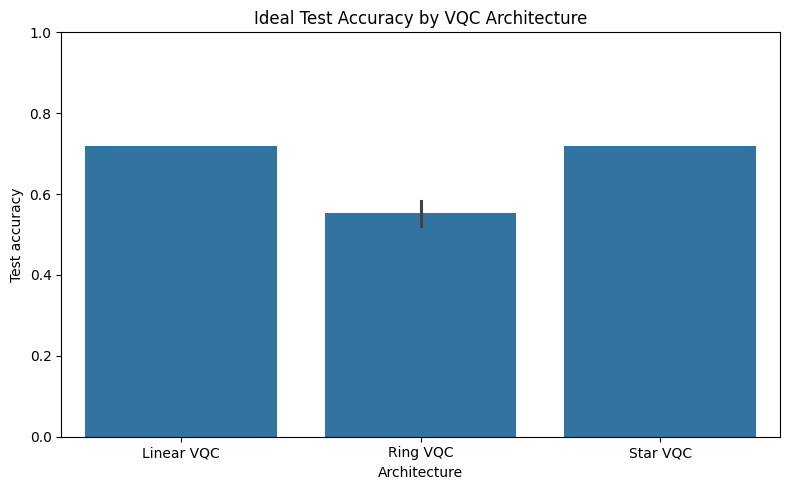

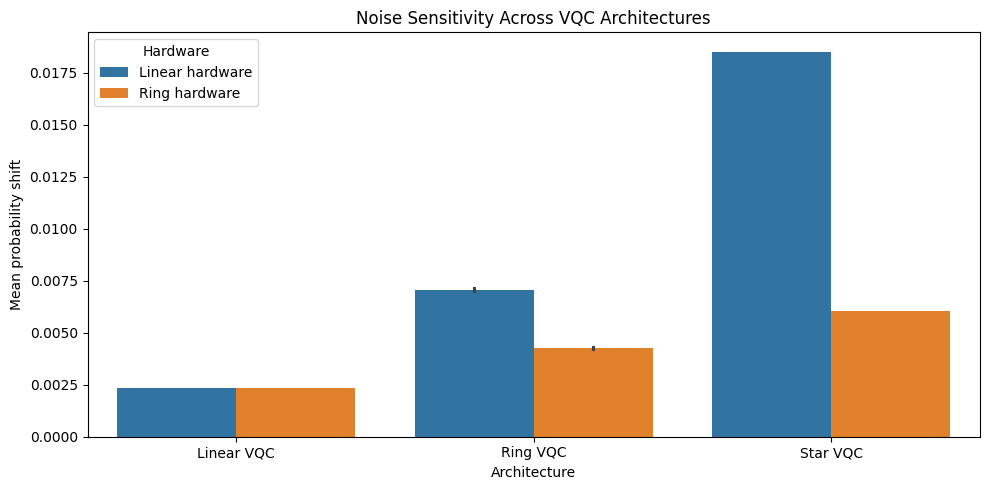

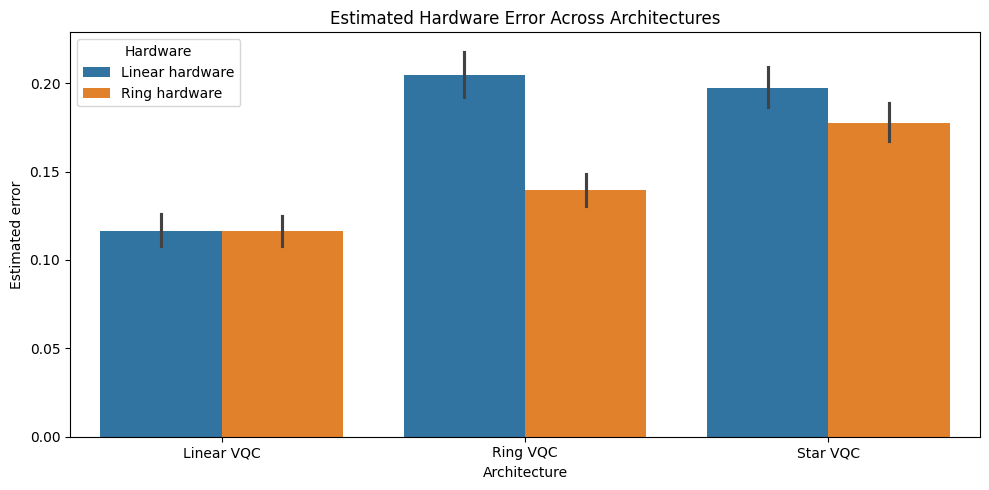

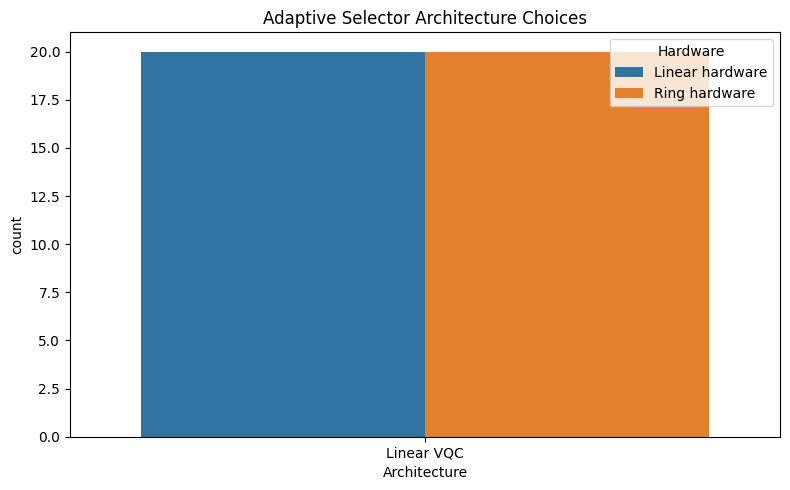

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Ideal accuracy
plt.figure(figsize=(8,5))
sns.barplot(
    data=all_ideal_results,
    x="Architecture",
    y="Test accuracy"
)
plt.title("Ideal Test Accuracy by VQC Architecture")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

# Plot 2: Noisy probability shifts
plt.figure(figsize=(10,5))
sns.barplot(
    data=all_noisy_df,
    x="Architecture",
    y="Mean probability shift",
    hue="Hardware"
)
plt.title("Noise Sensitivity Across VQC Architectures")
plt.tight_layout()
plt.show()

# Plot 3: Hardware implementation cost
plt.figure(figsize=(10,5))
sns.barplot(
    data=final_selector_df,
    x="Architecture",
    y="Estimated error",
    hue="Hardware"
)
plt.title("Estimated Hardware Error Across Architectures")
plt.tight_layout()
plt.show()

# Plot 4: Architecture selection
plt.figure(figsize=(8,5))
sns.countplot(
    data=final_selected,
    x="Architecture",
    hue="Hardware"
)
plt.title("Adaptive Selector Architecture Choices")
plt.tight_layout()
plt.show()

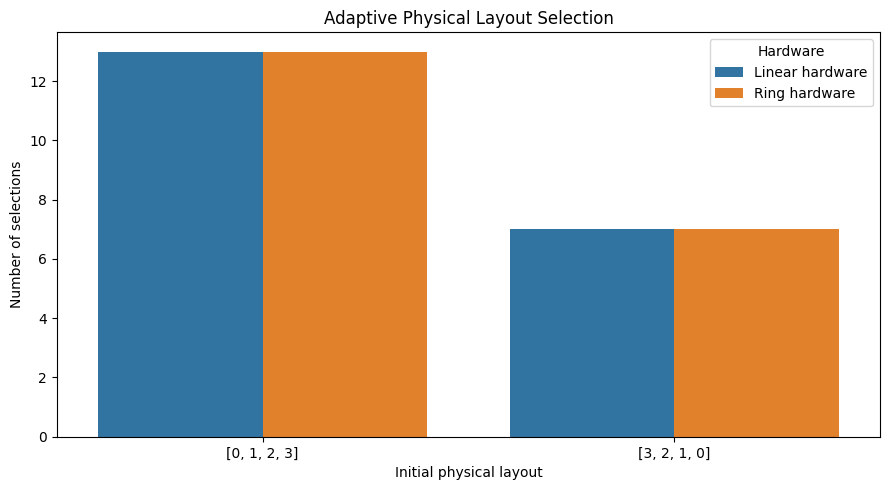

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=final_selected,
    x="Layout",
    hue="Hardware",
    order=["[0, 1, 2, 3]", "[3, 2, 1, 0]"]
)

plt.title("Adaptive Physical Layout Selection")
plt.xlabel("Initial physical layout")
plt.ylabel("Number of selections")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Pauli

linear_circuit = vqc_circuits["Linear VQC"]
linear_params = retrained_parameters["Linear VQC"][0]

# Create a copy of the circuit without CX gates
linear_no_cx = QuantumCircuit(4)

for instruction in linear_circuit.data:
    if instruction.operation.name != "cx":
        linear_no_cx.append(
            instruction.operation,
            instruction.qubits,
            instruction.clbits
        )

def predict_with_observable(circuit, params, sample, observable):
    bindings = {
        x_params[i]: sample[i] for i in range(4)
    }
    bindings.update({
        theta[i]: params[i] for i in range(8)
    })

    bound = circuit.assign_parameters(bindings)
    state = Statevector.from_instruction(bound)
    expectation = state.expectation_value(observable).real

    return (1 - expectation) / 2

original_probabilities = []
no_cx_probabilities = []

for sample in X_test_scaled:
    original_probabilities.append(
        predict_with_observable(
            linear_circuit, linear_params, sample, Pauli("IIIZ")
        )
    )

    no_cx_probabilities.append(
        predict_with_observable(
            linear_no_cx, linear_params, sample, Pauli("IIIZ")
        )
    )

original_probabilities = np.array(original_probabilities)
no_cx_probabilities = np.array(no_cx_probabilities)

print("Original Linear VQC loss:",
      np.mean((original_probabilities - y_test)**2))

print("Linear VQC without CX loss:",
      np.mean((no_cx_probabilities - y_test)**2))

print("Maximum probability difference:",
      np.max(np.abs(original_probabilities - no_cx_probabilities)))

Original Linear VQC loss: 0.19772199468033358
Linear VQC without CX loss: 0.19772199468033358
Maximum probability difference: 1.1102230246251565e-16


In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector, Pauli

# Measure qubit 3 instead of qubit 0
MEASURED_OBSERVABLE = Pauli("ZIII")

def predict_proba_q3(circuit, params, X_data):
    probabilities = []

    for sample in X_data:
        bindings = {
            x_params[i]: sample[i] for i in range(4)
        }
        bindings.update({
            theta[i]: params[i] for i in range(8)
        })

        bound_circuit = circuit.assign_parameters(bindings)
        state = Statevector.from_instruction(bound_circuit)

        expectation = state.expectation_value(
            MEASURED_OBSERVABLE
        ).real

        probabilities.append((1 - expectation) / 2)

    return np.array(probabilities)


def objective_q3(params, circuit):
    predictions = predict_proba_q3(
        circuit, params, X_train_scaled
    )
    return np.mean((predictions - y_train) ** 2)


# Retrain all architectures using identical settings
q3_trained_parameters = {}
q3_training_records = []

for architecture, circuit in vqc_circuits.items():

    q3_trained_parameters[architecture] = []

    for seed in range(5):

        rng = np.random.default_rng(seed)
        initial_parameters = rng.uniform(-np.pi, np.pi, 8)

        result = minimize(
            objective_q3,
            initial_parameters,
            args=(circuit,),
            method="COBYLA",
            options={"maxiter": 500}
        )

        q3_trained_parameters[architecture].append(result.x)

        q3_training_records.append({
            "Architecture": architecture,
            "Seed": seed,
            "Training loss": result.fun,
            "Iterations/evaluations": result.nfev,
            "Converged": result.success
        })

q3_training_df = pd.DataFrame(q3_training_records)

print("Retraining completed.")
display(q3_training_df)

print("\nMean training loss by architecture:")
display(
    q3_training_df.groupby("Architecture")["Training loss"]
    .agg(["mean", "std"])
)

Retraining completed.


,Architecture,Seed,Training loss,Iterations/evaluations,Converged
0,Linear VQC,0,0.227005,150,True
1,Linear VQC,1,0.227005,191,True
2,Linear VQC,2,0.227005,134,True
3,Linear VQC,3,0.227005,164,True
4,Linear VQC,4,0.227005,195,True
5,Ring VQC,0,0.227005,150,True
6,Ring VQC,1,0.227005,191,True
7,Ring VQC,2,0.227005,134,True
8,Ring VQC,3,0.227005,164,True
9,Ring VQC,4,0.227005,195,True



Mean training loss by architecture:


,mean,std
Architecture,,
Linear VQC,0.227005,4.286110e-11
Ring VQC,0.227005,4.286110e-11
Star VQC,0.203582,8.756937e-12


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

q3_test_results = []

for architecture, circuit in vqc_circuits.items():

    for seed, params in enumerate(q3_trained_parameters[architecture]):

        probabilities = predict_proba_q3(
            circuit, params, X_test_scaled
        )

        predictions = (probabilities >= 0.5).astype(int)

        q3_test_results.append({
            "Architecture": architecture,
            "Seed": seed,
            "Test loss": mean_squared_error(y_test, probabilities),
            "Accuracy": accuracy_score(y_test, predictions),
            "F1 score": f1_score(y_test, predictions)
        })

q3_test_df = pd.DataFrame(q3_test_results)

print("TEST PERFORMANCE — QUBIT 3 OBSERVABLE")
display(
    q3_test_df.groupby("Architecture")[
        ["Test loss", "Accuracy", "F1 score"]
    ].agg(["mean", "std"]).round(4)
)

TEST PERFORMANCE — QUBIT 3 OBSERVABLE


Test loss      Accuracy      F1 score     
                  mean  std     mean  std     mean  std
Architecture                                           
Linear VQC      0.2414  0.0     0.52  0.0   0.3333  0.0
Ring VQC        0.2414  0.0     0.52  0.0   0.3333  0.0
Star VQC        0.2138  0.0     0.64  0.0   0.6087  0.0

In [ ]:
from qiskit.quantum_info import SparsePauliOp, DensityMatrix

def noisy_prediction(compiled_circuit, sample, parameters, simulator):

    bindings = {
        x_params[i]: sample[i] for i in range(4)
    }
    bindings.update({
        theta[i]: parameters[i] for i in range(8)
    })

    bound = compiled_circuit.assign_parameters(bindings)

    # Measure logical qubit 3
    logical_observable = SparsePauliOp.from_list([
        ("ZIII", 1.0)
    ])

    physical_observable = logical_observable.apply_layout(
        compiled_circuit.layout
    )

    bound.save_density_matrix()

    result = simulator.run(bound).result()
    rho = DensityMatrix(result.data(0)["density_matrix"])

    expectation = rho.expectation_value(
        physical_observable
    ).real

    return (1 - expectation) / 2

In [ ]:
print("Number of compiled circuits:", len(compiled_circuits))

print("\nAvailable keys:")
for key in compiled_circuits.keys():
    print(key)

print("\nAvailable simulators:")
for key in simulators.keys():
    print(key)

Number of compiled circuits: 4

Available keys:
('Linear hardware', 'Linear VQC')
('Linear hardware', 'Ring VQC')
('Ring hardware', 'Linear VQC')
('Ring hardware', 'Ring VQC')

Available simulators:


NameError: name 'simulators' is not defined

In [ ]:

print("Available variables:")

for name in globals():
    if any(word in name.lower() for word in [
        "simulator", "backend", "noise", "calibration"
    ]):
        value = globals()[name]
        print(name, ":", type(value).__name__)

Available variables:
AerSimulator : ABCMeta
linear_calibration : dict
ring_calibration : dict
estimate_noise_exposure : function
noise_results : list
calibration : dict
noise_df : DataFrame
NoiseModel : type
build_noise_model : function
linear_noise : NoiseModel
ring_noise : NoiseModel
linear_simulator : AerSimulator
ring_simulator : AerSimulator
simulator : AerSimulator
calibration_profiles : dict
hardware_simulators : dict


In [ ]:
from qiskit import transpile

for hardware in ["Linear hardware", "Ring hardware"]:

    key = (hardware, "Star VQC")

    if key not in compiled_circuits:

        initial_layout = (
            [0, 1, 2, 3]
            if hardware == "Linear hardware"
            else [0, 1, 2, 3]
        )

        compiled_circuits[key] = transpile(
            vqc_circuits["Star VQC"],
            basis_gates=["id", "rz", "sx", "x", "cx"],
            optimization_level=1,
            initial_layout=initial_layout
        )

print("Compiled circuit keys:")
for key in compiled_circuits:
    print(key)

Compiled circuit keys:
('Linear hardware', 'Linear VQC')
('Linear hardware', 'Ring VQC')
('Ring hardware', 'Linear VQC')
('Ring hardware', 'Ring VQC')
('Linear hardware', 'Star VQC')
('Ring hardware', 'Star VQC')


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

hardware_simulators = {
    "Linear hardware": linear_simulator,
    "Ring hardware": ring_simulator
}

noisy_results_q3 = []

for architecture, circuit in vqc_circuits.items():

    for hardware in ["Linear hardware", "Ring hardware"]:

        compiled_circuit = compiled_circuits[
            (hardware, architecture)
        ]

        simulator = hardware_simulators[hardware]

        for seed, params in enumerate(
            q3_trained_parameters[architecture]
        ):

            probabilities = []

            for sample in X_test_scaled:
                p = noisy_prediction(
                    compiled_circuit,
                    sample,
                    params,
                    simulator
                )
                probabilities.append(p)

            probabilities = np.array(probabilities)
            predictions = (probabilities >= 0.5).astype(int)

            noisy_results_q3.append({
                "Architecture": architecture,
                "Hardware": hardware,
                "Seed": seed,
                "Test loss": mean_squared_error(
                    y_test, probabilities
                ),
                "Accuracy": accuracy_score(
                    y_test, predictions
                ),
                "F1 score": f1_score(
                    y_test, predictions
                )
            })

noisy_q3_df = pd.DataFrame(noisy_results_q3)

display(
    noisy_q3_df.groupby(
        ["Architecture", "Hardware"]
    )[["Test loss", "Accuracy", "F1 score"]]
    .agg(["mean", "std"])
    .round(4)
)

Test loss      Accuracy      F1 score     
                                  mean  std     mean  std     mean  std
Architecture Hardware                                                  
Linear VQC   Linear hardware    0.2417  0.0     0.52  0.0   0.3333  0.0
             Ring hardware      0.2417  0.0     0.52  0.0   0.3333  0.0
Ring VQC     Linear hardware    0.2419  0.0     0.52  0.0   0.3333  0.0
             Ring hardware      0.2417  0.0     0.52  0.0   0.3333  0.0
Star VQC     Linear hardware    0.2142  0.0     0.64  0.0   0.6087  0.0
             Ring hardware      0.2144  0.0     0.64  0.0   0.6087  0.0

In [ ]:
for name in globals():
    if any(word in name.lower() for word in [
        "selection", "selected", "selector", "layout", "hardware_cost"
    ]):
        value = globals()[name]
        print(name, ":", type(value).__name__)

calculate_hardware_cost : function
adaptive_selection : DataFrame
selected_df : DataFrame
layouts : list
layout : list
final_selector_results : list
final_selector_df : DataFrame
final_selected : DataFrame
initial_layout : list


In [ ]:
print("FINAL SELECTOR SUMMARY")

print("\nSelected architecture counts:")
display(
    final_selected["Architecture"].value_counts()
    if "Architecture" in final_selected.columns
    else final_selected.head()
)

print("\nSelected layout counts:")
display(
    final_selected["Layout"].value_counts()
    if "Layout" in final_selected.columns
    else final_selected.head()
)

print("\nFinal selector columns:")
print(final_selector_df.columns.tolist())

print("\nFinal selector preview:")
display(final_selector_df.head())

FINAL SELECTOR SUMMARY

Selected architecture counts:


,count
Architecture,
Linear VQC,40



Selected layout counts:


,count
Layout,
"[0, 1, 2, 3]",26
"[3, 2, 1, 0]",14



Final selector columns:
['Profile', 'Hardware', 'Architecture', 'Layout', 'Estimated error', 'Depth', 'CX gates', 'Normalized depth', 'Selection score']

Final selector preview:


,Profile,Hardware,Architecture,Layout,Estimated error,Depth,CX gates,Normalized depth,Selection score
0,Profile 1,Linear hardware,Linear VQC,"[0, 1, 2, 3]",0.060763,13,3,0.684211,0.185452
1,Profile 1,Linear hardware,Linear VQC,"[3, 2, 1, 0]",0.060763,13,3,0.684211,0.185452
2,Profile 1,Linear hardware,Linear VQC,"[0, 2, 1, 3]",0.089928,16,6,0.842105,0.240364
3,Profile 1,Linear hardware,Linear VQC,"[3, 1, 2, 0]",0.089928,16,6,0.842105,0.240364
4,Profile 1,Linear hardware,Ring VQC,"[0, 1, 2, 3]",0.105783,16,8,0.842105,0.253048


In [ ]:
tie_counts = (
    final_selector_df
    .groupby(["Profile", "Hardware"])["Selection score"]
    .apply(lambda x: (x == x.min()).sum())
)

print("Cases with tied minimum scores:",
      (tie_counts > 1).sum(), "out of", len(tie_counts))

print("\nNumber of tied selections:")
print(tie_counts.value_counts().sort_index())

Cases with tied minimum scores: 12 out of 40

Number of tied selections:
Selection score
1    28
2    12
Name: count, dtype: int64


In [ ]:

final_selected_corrected = (
    final_selector_df
    .sort_values(
        ["Profile", "Hardware", "Selection score", "Layout"],
        ascending=[True, True, True, True],
        kind="stable"
    )
    .drop_duplicates(
        subset=["Profile", "Hardware"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("Final selected configurations:",
      len(final_selected_corrected))

print("\nArchitecture counts:")
display(final_selected_corrected["Architecture"].value_counts())

print("\nLayout counts:")
display(final_selected_corrected["Layout"].value_counts())

Final selected configurations: 40

Architecture counts:


,count
Architecture,
Linear VQC,40



Layout counts:


,count
Layout,
"[0, 1, 2, 3]",26
"[3, 2, 1, 0]",14


In [ ]:
# Export corrected experiment results

q3_test_df.to_csv("corrected_ideal_results.csv", index=False)
noisy_q3_df.to_csv("corrected_noisy_results.csv", index=False)
final_selected_corrected.to_csv(
    "corrected_layout_selection.csv", index=False
)

print("Exported:")
print("1. corrected_ideal_results.csv")
print("2. corrected_noisy_results.csv")
print("3. corrected_layout_selection.csv")

Exported:
1. corrected_ideal_results.csv
2. corrected_noisy_results.csv
3. corrected_layout_selection.csv


In [ ]:
from google.colab import files

files.download("corrected_ideal_results.csv")
files.download("corrected_noisy_results.csv")
files.download("corrected_layout_selection.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>